# Bays (2024) Figure 5 — Diagnosing the $\mathrm{SD}_{\mathrm{normal}}$ Plateau (Bays vs GP)

**Goal.** Reproduce Figure 5 of Ma, Husain & Bays (2014, *Nat Neurosci*) using **two model pipelines run in parallel** under the same diagnostic protocol:

1. **Bays (2014) parametric population coding model.**
2. **Our GP-based population coding model.**

This is the same Bays-vs-GP equivalence comparison used throughout the thesis. Here it is applied to the $\mathrm{SD}_{\mathrm{normal}}$-plateau diagnostic: a methodological test that asks whether a particular way of *summarising* recall errors can be trusted to distinguish between competing accounts of working memory.

### What Figure 5 is about

A popular analysis pipeline for visual working memory data fits the Zhang & Luck (2008) **normal–uniform mixture**

$$
p(\epsilon) \;=\; w \cdot \mathrm{VonMises}(\epsilon;\, 0, \kappa) \;+\; (1-w) \cdot \frac{1}{2\pi}.
$$

From the fitted $\kappa$ one reads off $\mathrm{SD}_{\mathrm{normal}}$, intended as the precision of "stored" items, while $1-w$ is interpreted as the "guess" rate. Figure 5 of Ma, Husain & Bays (2014) shows that as set size $\ell$ grows:

- $\mathrm{SD}_{\mathrm{actual}}$ (the model-free circular SD of the raw errors) climbs steeply,
- $\mathrm{SD}_{\mathrm{normal}}$ (read off the fitted mixture) rises and then *plateaus*,
- $w$ drops — the mixture starts attributing errors to "guessing".

The plateau was used to argue for slot models: *"precision is fixed, extra items just fail to be stored."* The original paper's Figure 5(c) rebuts this by showing the same plateau pattern is produced by a continuous-resource model that contains **no slots and no item limit** — confirming the plateau is an artifact of fitting a misspecified mixture, not a signature of slots.

### What this notebook does

Both model pipelines are continuous-resource population coding models without slots. Running both through the identical diagnostic pipeline lets us check two things at once:

- That **each** model independently reproduces the $\mathrm{SD}_{\mathrm{normal}}$ plateau (so the diagnostic conclusion in Ma, Husain & Bays 2014 carries over to both architectures).
- That the **Bays and GP variants** produce quantitatively similar $\mathrm{SD}_{\mathrm{actual}}$ / $\mathrm{SD}_{\mathrm{normal}}$ curves under the protocol — the equivalence check that anchors the thesis.

### Layout

- **Row 1 — Bays parametric.** (a) aggregate-error distribution + mixture fit. (b) $\mathrm{SD}_{\mathrm{actual}}$ vs $\mathrm{SD}_{\mathrm{normal}}$ across set sizes.
- **Row 2 — GP variant.** Same two panels for the GP-based population.

### Note on the citation

The paper is Ma, Husain & Bays (2014, *Nat Neurosci*); a number of internal references in this project use the shorthand "Bays 2024" for the 2024 review article that re-presents the same figure. The diagnostic logic and figure are from the 2014 paper.

## What changed in this version (thesis corrections)

The diagnostic itself is unchanged: the same Bays parametric pipeline, the same GP
forward model (`Population`, `tuning_type='gp'`), the same Zhang & Luck mixture fit,
the same set sizes 1-8, trial counts and histogram cost, the same three-parameter
fit of the GP to the Bays errors, and the same one-parameter sensitivity sweeps.

What changed, and why:

1. **Population seeds (Correction 3).** The GP fit, the set-size sweep and the
   sensitivity sweeps are repeated at `N_SEEDS` independent population draws. The
   Bays population is deterministic, so its row is repeated over `N_SEEDS` fresh
   trial sets. Every reported number is a mean with a 95% confidence interval.
   Replicate 0 uses the original seed, and its Bays errors remain the fit target.
2. **Fitting: grid + Nelder-Mead instead of least_squares** (as in Experiments 2,
   3 and 5). The cost is piecewise constant, so finite-difference gradients are
   unreliable: the previous fit stopped after four steps on its tolerance. With a
   derivative-free search, 1,000 trials per evaluation suffice (as in Experiments 2
   and 5); 5,000 were needed only for least_squares' Jacobian.
3. **M = 100, and the fit and the sweep use the same M.** The notebook fitted at
   M = 100 and then ran the sweep at M = 1000 with the same total gain, assuming
   the GP's errors depend only on total gain. Experiment 2 showed they also depend
   on M, so the M = 1000 sweep was not the fitted model. As the notebook itself
   notes, with M = 100 "nothing is approximated". This is also the rule used for
   every fit to the Bays reference.
4. **Gamma sampler** for the main text (it was `sparse_broad`; the thesis caption
   already says gamma). The other samplers are for the appendix.
5. **Formal tests** of the three claims the text makes, per model: non-normality at
   one item, the SD_normal plateau (SD_actual keeps rising after SD_normal levels
   off), and a guess weight that rises with load; plus GP-minus-Bays differences
   with confidence intervals.
6. **Figures (Correction 7).** Error bars and 95% intervals on every summary
   statistic; every axis keeps at least two labelled ticks; each figure cell prints
   which axes are log for the caption. The 8-panel figure's "stored fraction" label
   is corrected: 1 − w is the guess (uniform) weight, not the stored fraction.

## GP Pipeline Comparison with Bays

**Experiment 1.** Run the Bays (2014) parametric population-coding model and the GP-based population model through the identical $\mathrm{SD}_{\mathrm{normal}}$-plateau diagnostic, and check that the two architectures behave equivalently. Everything below (setup, both forward models, the parameter fit, the set-size sweeps, and the headline Figure 5 reproduction) belongs to this experiment.

### Imports & setup

In [1]:
import sys
from pathlib import Path
from datetime import datetime

# Project root is two levels above this notebook
# (notebook lives in equivalence_model_v0.1/experiments/<something>/).
PROJECT_ROOT = Path.cwd().parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import time
from scipy.special import i0, i1
from scipy.optimize import minimize, least_squares

from core.population import Population

print(f"Project root: {PROJECT_ROOT}")


Project root: /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model


### Output directory

Results (figure + per-set-size summary) go to `result_data/bays_fig5_<timestamp>/`, matching the project's convention used by the other experiment notebooks.

In [2]:
import uuid

TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_UUID  = str(uuid.uuid4())          # unique id for this run; stamped into the fit DB

# Save beside the notebook, inside THIS experiment's own folder
# (experiments/<experiment>/result_data/...). The 8-char UUID suffix links
# the folder to its row in the fit database.
EXPERIMENT_DIR = Path.cwd()
OUTPUT_DIR = EXPERIMENT_DIR / "result_data" / f"bays_fig5_{TIMESTAMP}_{RUN_UUID[:8]}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Persistent fit database: accumulates ONE row per run (NOT timestamped, so
# it survives across runs and kernels). Created with a header on first use.
FIT_DB_PATH = EXPERIMENT_DIR / "fit_database.csv"

print(f"Experiment dir  : {EXPERIMENT_DIR}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Run UUID        : {RUN_UUID}")
print(f"Fit database    : {FIT_DB_PATH}")

Experiment dir  : /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2024
Output directory: /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2024/result_data/bays_fig5_20261020_211045_1f544647
Run UUID        : 1f544647-9759-48ef-aff2-9c82df4d2dba
Fit database    : /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2024/fit_database.csv


### Circular statistics and the Zhang & Luck mixture fit

In [3]:
def circular_sd(errors):
    """Fisher (1995) circular SD: sigma = sqrt(-2 log |m1|)."""
    R = np.abs(np.mean(np.exp(1j * np.asarray(errors))))
    return np.sqrt(-2.0 * np.log(max(R, 1e-15)))


def kappa_to_circular_sd(kappa):
    """Von Mises concentration kappa -> Fisher circular SD."""
    if kappa < 1e-6:
        return np.sqrt(-2.0 * np.log(1e-15))
    if kappa > 700:
        kappa = 700.0
    R = float(i1(kappa) / i0(kappa))
    return np.sqrt(-2.0 * np.log(max(R, 1e-15)))


def _neg_log_lik_mixture(unconstrained_params, errors):
    """Negative log likelihood of the normal-uniform mixture, with logit/log transforms."""
    logit_w, log_kappa = unconstrained_params
    w = 1.0 / (1.0 + np.exp(-logit_w))
    kappa = np.exp(log_kappa)

    vm = np.exp(kappa * np.cos(errors)) / (2.0 * np.pi * i0(kappa))
    uniform = 1.0 / (2.0 * np.pi)
    mix = w * vm + (1.0 - w) * uniform

    return -np.sum(np.log(np.maximum(mix, 1e-300)))


def fit_normal_uniform_mixture(errors, init_w=0.85, init_kappa=10.0):
    """
    ML fit of the Zhang & Luck (2008) normal-uniform mixture.

    Returns
    -------
    w : float in (0, 1)
        Weight on the Von Mises ("stored") component.
    kappa : float > 0
        Von Mises concentration.
    sd_normal : float
        Circular SD corresponding to kappa.
    """
    errors = np.asarray(errors)
    logit_w0 = np.log(init_w / (1.0 - init_w))
    log_kappa0 = np.log(init_kappa)
    x0 = np.array([logit_w0, log_kappa0])

    result = minimize(
        _neg_log_lik_mixture, x0, args=(errors,),
        method="Nelder-Mead",
        options={"xatol": 1e-6, "fatol": 1e-6, "maxiter": 5000},
    )
    logit_w, log_kappa = result.x
    w = 1.0 / (1.0 + np.exp(-logit_w))
    kappa = np.exp(log_kappa)
    sd_normal = kappa_to_circular_sd(kappa)
    return w, kappa, sd_normal


# Sanity check: a pure von Mises should give w ~ 1, SD_actual ~ SD_normal
rng_test = np.random.RandomState(0)
test_errors = rng_test.vonmises(0, 5.0, size=5000)
w_hat, k_hat, sd_n_hat = fit_normal_uniform_mixture(test_errors)
print("Sanity check (pure VM with kappa=5):")
print(f"  fitted w={w_hat:.3f} (should be near 1), kappa={k_hat:.2f} (should be ~5)")
print(f"  SD_actual={np.rad2deg(circular_sd(test_errors)):.2f} deg, "
      f"SD_normal={np.rad2deg(sd_n_hat):.2f} deg  (should be ~equal)")


Sanity check (pure VM with kappa=5):
  fitted w=1.000 (should be near 1), kappa=5.07 (should be ~5)
  SD_actual=26.99 deg, SD_normal=26.99 deg  (should be ~equal)


### Seed statistics, the shared fitter and the axis rules

Means with t-based 95% confidence intervals across seeds; Holm correction for
multiple tests; the grid + Nelder-Mead search used in Experiments 2, 3 and 5; and
the axis helpers that keep at least two labelled ticks on every axis.

In [4]:
# === Seed statistics, the shared fitter, and axis rules (thesis corrections) ===
from types import SimpleNamespace
from scipy import stats
from matplotlib.ticker import FixedLocator, NullLocator, FuncFormatter, MaxNLocator


def mean_ci(values, conf=0.95):
    """Mean over axis 0 with a t-based CI. Returns (mean, lo, hi)."""
    x = np.asarray(values, dtype=float)
    m = np.nanmean(x, axis=0)
    if x.shape[0] < 2:
        return m, m, m
    half = stats.t.ppf(0.5 + conf / 2, x.shape[0] - 1) * np.nanstd(x, axis=0, ddof=1) / np.sqrt(x.shape[0])
    return m, m - half, m + half


def welch_diff_ci(a, b, conf=0.95):
    """Mean of a minus mean of b, with a Welch CI (unequal variances)."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    se = np.sqrt(va + vb)
    df = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1)) if se > 0 else 1.0
    d = a.mean() - b.mean()
    half = stats.t.ppf(0.5 + conf / 2, df) * se
    return d, d - half, d + half


def holm(pvalues):
    """Holm-Bonferroni adjusted p-values (NaN entries stay NaN)."""
    p = np.asarray(pvalues, dtype=float)
    adjusted = np.full_like(p, np.nan)
    ok = np.where(np.isfinite(p))[0]
    order = ok[np.argsort(p[ok])]
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(ok) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted


def sse_cost(residual_vector):
    """0.5 * sum of squared residuals (the least_squares 'cost' scale)."""
    r = np.asarray(residual_vector, dtype=float)
    return 0.5 * float(r @ r)


def fit_grid_nm(cost_fn, candidates, lo, hi, nm_maxfev=80, nm_step=0.15):
    """Grid search, then Nelder-Mead in log-parameters (as in Experiments 2, 3, 5).
    Never returns worse than the best grid point."""
    lo = np.asarray(lo, dtype=float)
    hi = np.asarray(hi, dtype=float)
    floor_lo = np.maximum(lo, 1e-6)
    log_lo, log_hi = np.log(floor_lo), np.log(hi)
    memo = {}

    def evaluate(x):
        x = np.clip(np.asarray(x, dtype=float), floor_lo, hi)
        key = tuple(np.round(np.log(x), 6))
        if key not in memo:
            memo[key] = float(cost_fn(x))
        return memo[key]

    grid_x = [np.clip(np.asarray(c, dtype=float), floor_lo, hi) for c in candidates]
    grid_cost = np.array([evaluate(x) for x in grid_x])
    i_best = int(np.argmin(grid_cost))
    x_grid_best = grid_x[i_best]
    gx = np.array(grid_x)
    at_edge = []
    for j in range(gx.shape[1]):
        vals = np.unique(np.round(gx[:, j], 9))
        if vals.size > 2 and (np.isclose(x_grid_best[j], vals[0]) or
                              np.isclose(x_grid_best[j], vals[-1])):
            at_edge.append(j)
    z0 = np.log(x_grid_best)
    simplex = np.vstack([z0] + [z0 + nm_step * np.eye(z0.size)[j] for j in range(z0.size)])
    nm = minimize(lambda z: evaluate(np.exp(np.clip(z, log_lo, log_hi))), z0,
                  method='Nelder-Mead',
                  options=dict(initial_simplex=simplex, xatol=0.01, fatol=1e-4,
                               maxfev=nm_maxfev, adaptive=True))
    x_best = np.exp(np.clip(nm.x, log_lo, log_hi))
    cost_best = evaluate(x_best)
    if grid_cost[i_best] < cost_best:
        x_best, cost_best = x_grid_best, float(grid_cost[i_best])
    return SimpleNamespace(x=x_best, cost=float(cost_best), nfev=len(memo),
                           at_grid_edge=at_edge,
                           nm_moved_log=float(np.max(np.abs(np.log(x_best) - np.log(x_grid_best)))))


def _tick_label(value, _pos=None):
    return f'{value:g}'


def log_ylim(values, pad=1.6):
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v) & (v > 0)]
    if v.size == 0:
        return 0.01, 10.0
    return v.min() / pad, v.max() * pad


def log_y_axis(ax, lo, hi):
    """Log y-axis with at least two labelled ticks inside [lo, hi]."""
    ax.set_yscale('log')
    ax.set_ylim(lo, hi)
    k0, k1 = int(np.floor(np.log10(lo))), int(np.ceil(np.log10(hi)))
    ticks = [10.0 ** k for k in range(k0, k1 + 1) if lo <= 10.0 ** k <= hi]
    if len(ticks) < 2:
        ticks = [m * 10.0 ** k for k in range(k0 - 1, k1 + 1) for m in (1, 2, 5)
                 if lo <= m * 10.0 ** k <= hi]
    if len(ticks) < 2:
        ticks = [lo, hi]
    while len(ticks) > 6:
        ticks = ticks[::2]
    ax.yaxis.set_major_locator(FixedLocator(ticks))
    ax.yaxis.set_minor_locator(NullLocator())
    ax.yaxis.set_major_formatter(FuncFormatter(_tick_label))


def kurtosis_axis_spec(values):
    """('log', lo, hi) if every value is positive, otherwise ('linear', lo, hi)."""
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    if v.size == 0:
        return ('linear', -1.0, 1.0)
    if v.min() > 0:
        lo, hi = log_ylim(v)
        return ('log', lo, hi)
    span = max(v.max() - v.min(), 1e-6)
    return ('linear', v.min() - 0.1 * span, v.max() + 0.1 * span)


THESIS_FIG_DIR = PROJECT_ROOT / 'simulated_experiments' / 'thesis_figures' / 'zhang_luck'


def save_with_thesis_copy(fig, run_name, thesis_name):
    """Save PNG + PDF to OUTPUT_DIR and to THESIS_FIG_DIR; confirm the files exist."""
    paths = []
    for folder, name in ((OUTPUT_DIR, run_name), (THESIS_FIG_DIR, thesis_name)):
        folder.mkdir(parents=True, exist_ok=True)
        for ext in ('png', 'pdf'):
            path = (folder / f'{name}.{ext}').resolve()
            fig.savefig(path, dpi=300, bbox_inches='tight')
            paths.append(path)
    missing = [str(p) for p in paths if not p.exists()]
    if missing:
        raise IOError(f'Figure not written: {missing}')
    return paths

print('Helpers ready.')

Helpers ready.


### Bays parametric pipeline

Standalone implementation of Bays (2014, *J Neurosci*) Experiment 1 — pure NumPy, no `core.*` dependencies. Same forward model as the Bays-2014 reference used in the rest of the thesis.

| Bays equation | What it does |
|---|---|
| Eq. 1 | Tuning: $f_i(\theta) = \exp(\omega^{-1}(\cos(\phi_i - \theta) - 1))$ |
| Eq. 2 / 3 | DN: $r_{ij} = \gamma \cdot f_{ij} / \sum_{m,n} f_{mn}$ |
| Eq. 4 | Independent Poisson spike counts over $T_d$ |
| Eqs. 5–8 | ML decoder: $\hat\theta = \arg\max_\theta \sum_i n_i \cos(\phi_i - \theta)$ |

Three details to flag: (i) **no** semi-saturation $\sigma^2$ in the DN denominator (Bays Eq. 2 has none); (ii) continuous orientation sampling (no encoding-grid quantisation); (iii) random tie-breaking in `argmax` per Bays's explicit spec.

In [5]:
def bays_run_trials(n_trials, set_size, omega, gamma_total, T_d,
                    M=100, rng=None, n_decode_grid=1000):
    """
    Vectorised batch implementation of Bays (2014) Experiment 1 pipeline.

    Returns signed circular errors of shape (n_trials,) in radians on [-pi, pi).
    """
    if rng is None:
        rng = np.random.RandomState()

    l = set_size
    phi = np.linspace(-np.pi, np.pi, M, endpoint=False)

    # 1-2. Sample stimuli
    theta_true = rng.uniform(-np.pi, np.pi, size=(n_trials, l))
    cued = rng.randint(l, size=n_trials)

    # 3. Eq. 1 driving inputs
    diff = phi[None, None, :] - theta_true[:, :, None]
    f = np.exp((1.0 / omega) * (np.cos(diff) - 1.0))

    # 4. DN -- denom is per-trial sum over (l, M)
    denom = f.sum(axis=(1, 2))
    rates = gamma_total * f / denom[:, None, None]

    # 5. Poisson spikes
    counts = rng.poisson(rates * T_d)

    # 6. Pull out probed subpopulation
    counts_probed = counts[np.arange(n_trials), cued, :]

    # ML decode (vectorised over trials)
    theta_eval = np.linspace(-np.pi, np.pi, n_decode_grid, endpoint=False)
    cos_grid = np.cos(phi[:, None] - theta_eval[None, :])
    objective = counts_probed @ cos_grid

    # Random tie-breaking
    max_vals = objective.max(axis=1, keepdims=True)
    tied_mask = objective >= max_vals - 1e-12
    keys = rng.random(objective.shape) * tied_mask
    chosen_idx = keys.argmax(axis=1)
    theta_hat = theta_eval[chosen_idx]

    # 7. Signed circular error
    d = theta_hat - theta_true[np.arange(n_trials), cued]
    return (d + np.pi) % (2.0 * np.pi) - np.pi


print("Defined: bays_run_trials")


Defined: bays_run_trials


### GP forward model

Routes through the unified `Population` class (`tuning_type='gp'`). `Population.run_trials` performs the same vectorised batch encode-and-decode as `bays_run_trials`: it samples `set_size` orientations on a deterministic location tuple, applies population-level divisive normalisation, generates Poisson spikes, and returns signed circular errors via the ML decoder. Setting `active_locations=tuple(range(set_size))` and `probe_cued=True` matches the convention of probing location 0 on every trial.

In [6]:
def build_gp_population(M, n_theta, omega, n_locations, seed,
                        lengthscale_variability=0.3, gain_variability=0.0,
                        method='folded_normal'):
    """
    Construct the heterogeneous GP population used downstream.

    Bays's tuning width `omega` maps to the GP lengthscale internally via
    `lambda = sqrt(omega)` (handled inside `Population._build_gp`).

    `method` selects the lengthscale sampler family ('folded_normal' or
    'gamma'); it is forwarded to Population so the same call site can
    switch sampler without touching the GP sweep cell.
    """
    return Population(
        M=M,
        n_theta=n_theta,
        omega=omega,
        tuning_type="gp",
        n_locations=n_locations,
        seed=seed,
        lengthscale_variability=lengthscale_variability,
        gain_variability=gain_variability,
        method=method,
    )


print("Defined: build_gp_population")


Defined: build_gp_population


### Configuration — all tunable knobs in one cell

Edit this single cell to change any experimental knob. Defaults follow Bays (2014) Experiment 1 group-mean ML parameters: $\omega = 0.52$, $\gamma_\mathrm{total} = 119$ Hz, $M = 100$, $T_d = 0.1$ s. The $\omega \leftrightarrow \lambda$ mapping ($\lambda = \sqrt{\omega}$) and the gain conversion ($\gamma_\mathrm{per\ neuron} = \gamma_\mathrm{total} / M$) make the GP variant numerically comparable to the Bays parametric model.

Re-run from this cell to apply changes — the model definitions above don't need to be touched.

In [7]:
# =============================================================
# === PARAMETERS - edit here to play with the experiment    ===
# =============================================================

# --- Shared (both Bays parametric and GP variant) ---
M = 100                            # THE single global neuron count for BOTH pipelines.
                                  #   100: the rule for every fit to the Bays reference (was 1000).
                                  #   Allowed: 100 / 1000 / 10000 (matches the Bays cache grid).
assert M in (100, 1000, 10000), f"M must be 100 / 1000 / 10000, got {M}."
DISTRIBUTION = 'sparse_broad'          # <-- SET ME: 'folded_normal' | 'gamma' | 'sparse_broad'
                                #     gamma for the main text; the others for the appendix

print(f'DISTRIBUTION = {DISTRIBUTION!r}')
assert DISTRIBUTION in ('folded_normal', 'gamma', 'sparse_broad'), (
    f"DISTRIBUTION must be 'folded_normal' / 'gamma' / 'sparse_broad', "
    f"got {DISTRIBUTION!r}"
)
N_TRIALS = 5000                   # trials per set size (per model)
T_D = 0.1                         # decoding window (s)
SET_SIZES = list(range(1, 9))     # set sizes to sweep: 1, 2, ..., 8
SEED = 42
N_SEEDS = 10                      # population seeds (GP) / trial replicates (Bays) (Correction 3)
SEED_STRIDE = 100_000             # replicate s shifts every seed by s * SEED_STRIDE

# --- Bays parametric model ---
OMEGA_BAYS = 0.52                 # tuning width (group-mean ML fit, Bays 2014 Fig 2b)
GAMMA_TOTAL_BAYS = 119.0          # total population gain (Hz)
N_DECODE_GRID = 1000              # orientation grid for Bays ML decoder

# --- Bays reference source: regenerate inline, or load cached .npz ---
# The cache is produced by build_bays_cache.py. Bays errors are M-invariant
# (Bays 2014: "error distributions were independent of population size"), so
# any cached M is a valid reference; the loader matches M for clarity.
# NOTE: the cache must cover every entry in SET_SIZES. The shipped builder
# only caches [1, 2, 4, 8]; rebuild it with SET_SIZES = list(range(1, 9))
# before flipping this to True, or the loader falls back to inline generation.
USE_BAYS_CACHE = False            # <-- set True once the cache covers all SET_SIZES
CACHE_DIR = PROJECT_ROOT / "cached_data"   # <-- confirm / override to your cached_data path

# --- GP variant ---
N_THETA_GP = 128                  # orientation grid resolution for GP tuning curves
LENGTHSCALE_VARIABILITY = 0.3     # spread of GP lengthscales across locations
GAIN_VARIABILITY = 0.0            # spread of amplitude scaling (0 = homogeneous)
SIGMA_SQ = 1e-6                   # DN semi-saturation constant

# --- Histogram (panel a) ---
HIST_N_BINS = 120                 # ~3 deg bins over [-180, 180]

# --- Derived (don't edit directly) ---
LAMBDA_BASE = np.sqrt(OMEGA_BAYS)
GAMMA_PER_NEURON = GAMMA_TOTAL_BAYS / M

print("=== Configuration ===")
print(f"M = {M} neurons (global, Bays AND GP),  T_D = {T_D}s,  N_TRIALS = {N_TRIALS} per set size")
print(f"Set sizes: {SET_SIZES}")
print()
print("Bays parametric:")
print(f"  omega = {OMEGA_BAYS}")
print(f"  gamma_total = {GAMMA_TOTAL_BAYS} Hz")
print(f"  decode grid = {N_DECODE_GRID}")
print(f"  reference source = {'cache (.npz)' if USE_BAYS_CACHE else 'inline'}")
print()
print("GP variant:")
print(f"  lambda = sqrt(omega) = {LAMBDA_BASE:.4f}")
print(f"  gamma_per_neuron = gamma_total / M = {GAMMA_PER_NEURON:.3f} Hz")
print(f"  n_theta = {N_THETA_GP}")
print(f"  lengthscale_variability = {LENGTHSCALE_VARIABILITY}")
print(f"  gain_variability = {GAIN_VARIABILITY}")
print()
print(f"Histogram bins (panel a): {HIST_N_BINS}  (~{360/HIST_N_BINS:.1f} deg wide)")

DISTRIBUTION = 'sparse_broad'
=== Configuration ===
M = 100 neurons (global, Bays AND GP),  T_D = 0.1s,  N_TRIALS = 5000 per set size
Set sizes: [1, 2, 3, 4, 5, 6, 7, 8]

Bays parametric:
  omega = 0.52
  gamma_total = 119.0 Hz
  decode grid = 1000
  reference source = inline

GP variant:
  lambda = sqrt(omega) = 0.7211
  gamma_per_neuron = gamma_total / M = 1.190 Hz
  n_theta = 128
  lengthscale_variability = 0.3
  gain_variability = 0.0

Histogram bins (panel a): 120  (~3.0 deg wide)


### Sweep the Bays parametric model across set sizes

For each $l$, generate `N_TRIALS` errors, then compute $\mathrm{SD}_{\mathrm{actual}}$ and
fit the Zhang & Luck mixture to extract $\mathrm{SD}_{\mathrm{normal}}$ and $w$. This is
repeated over `N_SEEDS` trial replicates. Replicate 0 is the original run and remains the
fixed target the GP is fitted to; the other replicates give the Bays row its confidence
intervals (the Bays population is deterministic, so only the trials change).

In [8]:
def _bays_cache_path(cache_dir, M, n_trials=10000, omega=OMEGA_BAYS,
                     gamma_total=GAMMA_TOTAL_BAYS, seed=12345):
    """Canonical Bays cache filename -- MUST match build_bays_cache.py."""
    return Path(cache_dir) / (
        f"bays_cache_omega{omega:g}_gamma{gamma_total:g}"
        f"_M{M}_N{n_trials}_seed{seed}.npz"
    )


def load_bays_errors_from_cache(cache_dir, M, set_sizes):
    """Return {set_size: errors} from a cache .npz, or None if unusable.

    Requires the cache to cover EVERY requested set size; otherwise returns
    None so the caller falls back to inline generation. We deliberately do
    NOT silently mix cached and freshly-generated set sizes.
    """
    path = _bays_cache_path(cache_dir, M)
    if not path.exists():
        print(f"[cache] not found: {path.name}  ->  regenerating inline")
        return None
    with np.load(path, allow_pickle=True) as z:
        have = {int(k.split("_N")[1]) for k in z.files if k.startswith("errors_N")}
        missing = [N for N in set_sizes if N not in have]
        if missing:
            print(f"[cache] {path.name} missing set sizes {missing} "
                  f"(has {sorted(have)})  ->  regenerating inline. "
                  f"Rebuild with SET_SIZES=list(range(1,9)) for full coverage.")
            return None
        errs = {N: z[f"errors_N{N}"] for N in set_sizes}
    print(f"[cache] loaded {path.name}  (set sizes {set_sizes})")
    return errs


def _bays_sweep(rng, cached=None):
    """One Bays replicate: errors, SD_actual and the mixture fit at every set size."""
    out = {}
    for N in SET_SIZES:
        if cached is not None:
            errors = cached[N]
        else:
            errors = bays_run_trials(
                n_trials=N_TRIALS, set_size=N,
                omega=OMEGA_BAYS, gamma_total=GAMMA_TOTAL_BAYS, T_d=T_D,
                M=M, rng=rng, n_decode_grid=N_DECODE_GRID,
            )
        sd_actual = circular_sd(errors)
        w_hat, kappa_hat, sd_normal = fit_normal_uniform_mixture(errors)
        out[N] = dict(errors=errors, sd_actual=sd_actual, sd_normal=sd_normal,
                      w=w_hat, kappa=kappa_hat)
    return out


t0 = time.time()
cached = load_bays_errors_from_cache(CACHE_DIR, M, SET_SIZES) if USE_BAYS_CACHE else None
BAYS_SOURCE = "cache" if cached is not None else "inline"

# Replicate 0: RandomState(SEED) consumed in set-size order, exactly as before.
BAYS_BY_SEED = []
for s in range(N_SEEDS):
    rng_bays = np.random.RandomState(SEED + SEED_STRIDE * s)
    BAYS_BY_SEED.append(_bays_sweep(rng_bays, cached if s == 0 else None))
bays_results = BAYS_BY_SEED[0]          # the fixed fit target, as before

print("Replicate 0 (the fit target):")
for N in SET_SIZES:
    r = bays_results[N]
    print(f"  Bays l={N}:  SD_actual={np.rad2deg(r['sd_actual']):6.2f} deg   "
          f"SD_normal={np.rad2deg(r['sd_normal']):6.2f} deg   "
          f"w={r['w']:.3f}   kappa={r['kappa']:.2f}")
print(f"Bays sweep ({BAYS_SOURCE}; {N_SEEDS} trial replicates) done in {time.time()-t0:.1f}s")

Replicate 0 (the fit target):
  Bays l=1:  SD_actual= 15.38 deg   SD_normal= 15.22 deg   w=0.999   kappa=14.69
  Bays l=2:  SD_actual= 24.34 deg   SD_normal= 22.16 deg   w=0.982   kappa=7.22
  Bays l=3:  SD_actual= 32.24 deg   SD_normal= 27.58 deg   w=0.956   kappa=4.88
  Bays l=4:  SD_actual= 39.53 deg   SD_normal= 30.50 deg   w=0.905   kappa=4.12
  Bays l=5:  SD_actual= 46.00 deg   SD_normal= 33.53 deg   w=0.858   kappa=3.53
  Bays l=6:  SD_actual= 50.04 deg   SD_normal= 34.83 deg   w=0.817   kappa=3.32
  Bays l=7:  SD_actual= 52.80 deg   SD_normal= 35.89 deg   w=0.792   kappa=3.17
  Bays l=8:  SD_actual= 59.06 deg   SD_normal= 37.13 deg   w=0.720   kappa=3.01
Bays sweep (inline; 10 trial replicates) done in 5.9s


### Sweep the GP variant across set sizes

#### GP experiment control

These flags govern the GP variant: first a fit of $(\lambda, \gamma, \sigma)$ against the Bays errors, then a GP sweep across set sizes at those fitted parameters. The Bays parametric sweep above is unaffected.

**`M_GP`** is the number of neurons for the GP population. Suggested values: `100` (primary reference, fast), `1000` (M-scaling diagnostic, slower), `10000` (large-M asymptotic, slowest).

**`DISTRIBUTION`** chooses how lengthscales are sampled across locations inside the GP forward model: `'folded_normal'` or `'gamma'`. The single $\sigma$ parameter (interpreted per-sampler) is a **scalar** — fitted once and applied uniformly across all locations.

The downstream Zhang & Luck mixture is fit to **GP errors generated at the fitted parameters**, not at Bays's raw $(\omega = 0.52, \gamma = 119)$ — so panels c/d test whether the GP-as-fit-to-Bays reproduces the same plateau, rather than testing whether an arbitrary GP at Bays-truth parameters does.


In [9]:
# === GP CONTROL (1/3): neuron count ===
# CONSOLIDATED: there is a single global `M` (set in the parameters cell
# above), used by BOTH the Bays and GP pipelines. There is no separate
# M any more -- the 100-vs-1000-vs-10000 comparison is driven entirely
# by the one global M.
print(f"M (global, used by Bays AND GP) = {M}")

M (global, used by Bays AND GP) = 100


In [10]:
# === GP CONTROL (3/3): resolved derived quantities ===
# Reads M and DISTRIBUTION from the cells above. Re-run this (and the GP
# cells below) after changing either.

GAMMA_PER_NEURON_GP = GAMMA_TOTAL_BAYS / M

print('=== GP experiment control resolved ===')
print(f'  M                   = {M}')
print(f'  DISTRIBUTION        = {DISTRIBUTION!r}')
print(f'  gamma_per_neuron_gp = {GAMMA_PER_NEURON_GP:.4f} Hz '
      f'(total stays at {GAMMA_TOTAL_BAYS} Hz)')

=== GP experiment control resolved ===
  M                   = 100
  DISTRIBUTION        = 'sparse_broad'
  gamma_per_neuron_gp = 1.1900 Hz (total stays at 119.0 Hz)


#### Step 1 — Fit GP $(\lambda, \gamma, \sigma)$ to the Bays errors, at every population seed

Same target and cost as before: the GP forward model's three free parameters are fitted
to the Bays error histograms (replicate 0), all set sizes at once. $\sigma$ (`sigma_lambda`
for folded-normal, `cv` for gamma) is a single scalar applied across all locations.

Changes: the search is the grid + Nelder-Mead of Experiments 2, 3 and 5; the fit runs at
the global M (so the sweep uses the population the fit saw); and the fit is repeated at
every population seed. Each seed's fit is cached to disk as soon as it finishes.

In [11]:
# === Step 1 — Fit GP (lambda, gamma, sigma) to the Bays errors, at every population seed ===
import hashlib, json as _json, pickle

N_TRIALS_FIT = 1000    # trials per set size per evaluation (as in Experiments 2 and 5);
                       # 5000 was only needed for least_squares' finite differences
SEED_FIT     = SEED
N_BINS_FIT   = 50
BIN_EDGES    = np.linspace(-np.pi, np.pi, N_BINS_FIT + 1)
M_FIT        = M       # fit and sweep now use the same population size

LAMBDA_TARGET = np.sqrt(OMEGA_BAYS)
GAMMA_TARGET  = GAMMA_TOTAL_BAYS / M_FIT
GAMMA_TOTAL_LO, GAMMA_TOTAL_HI = 5.0, 2000.0          # Hz, whole population
if DISTRIBUTION == 'folded_normal':
    X0 = [LAMBDA_TARGET, GAMMA_TARGET, 0.1]
    LO = [0.1, GAMMA_TOTAL_LO / M_FIT, 0.0]
    HI = [3.0, GAMMA_TOTAL_HI / M_FIT, 2.0]
    SIGMA_NAME = 'sigma_lambda'
elif DISTRIBUTION == 'gamma':
    X0 = [LAMBDA_TARGET, GAMMA_TARGET, 0.1]
    LO = [0.1, GAMMA_TOTAL_LO / M_FIT, 0.01]
    HI = [3.0, GAMMA_TOTAL_HI / M_FIT, 10.0]
    SIGMA_NAME = 'cv'
else:  # 'sparse_broad' -- broad/sharp k-hot mix; spread knob ~ folded-normal
    X0 = [LAMBDA_TARGET, GAMMA_TARGET, 0.1]
    LO = [0.1, GAMMA_TOTAL_LO / M_FIT, 0.0]
    HI = [3.0, GAMMA_TOTAL_HI / M_FIT, 2.0]
    SIGMA_NAME = 'sigma_lambda'

GRID_LAMBDA      = np.geomspace(0.35, 2.0, 6)
GRID_GAMMA_TOTAL = np.geomspace(20.0, 1280.0, 7)      # Hz, whole population
GRID_SIGMA       = max(0.1, LO[2])
NM_MAXFEV, NM_STEP = 80, 0.15
SEED_BASES     = [SEED_FIT + SEED_STRIDE * s for s in range(N_SEEDS)]
HELDOUT_OFFSET = 50_000     # held-out trials: never used by the fit
SHOW_OFFSET    = 7_000      # reported pools (sweep, sensitivity grid): fresh trials

# Fit target: replicate 0's Bays errors, concatenated across set sizes (as before).
data_hists = {N: np.histogram(bays_results[N]['errors'], bins=BIN_EDGES, density=True)[0]
              for N in SET_SIZES}
data_vector = np.concatenate([data_hists[N] for N in SET_SIZES])

# Noise floor: Bays at its own parameters on fresh trials, N_TRIALS_FIT per set size.
SELF_SEED = SEED + 424_242
_floor_pred = np.concatenate([
    np.histogram(bays_run_trials(N_TRIALS_FIT, N, OMEGA_BAYS, GAMMA_TOTAL_BAYS, T_D, M=M,
                                 rng=np.random.RandomState(SELF_SEED + N),
                                 n_decode_grid=N_DECODE_GRID),
                 bins=BIN_EDGES, density=True)[0]
    for N in SET_SIZES])
NOISE_FLOOR = sse_cost(data_vector - _floor_pred)

_pop_cache = {}
_POP_CACHE_MAX = 8


def gp_population(lam, sig, pop_seed):
    """GP population at (lambda, sigma) for one seed; built once and reused."""
    key = (round(float(lam), 6), round(float(sig), 6), int(pop_seed))
    pop = _pop_cache.get(key)
    if pop is None:
        pop = build_gp_population(
            M=M, n_theta=N_THETA_GP, omega=lam ** 2, n_locations=max(SET_SIZES),
            seed=pop_seed, lengthscale_variability=sig,
            gain_variability=GAIN_VARIABILITY, method=DISTRIBUTION,
        )
        _pop_cache[key] = pop
        while len(_pop_cache) > _POP_CACHE_MAX:
            _pop_cache.pop(next(iter(_pop_cache)))
    return pop


def gp_errors(pop, gamma_per_neuron, N, n_trials, trial_seed):
    return pop.run_trials(
        n_trials=n_trials, gamma=gamma_per_neuron, T_d=T_D, set_size=N,
        sigma_sq=SIGMA_SQ, rng=np.random.RandomState(trial_seed),
        active_locations=tuple(range(N)), probe_cued=True,
    )


def fit_cost_fn(pop_seed, offset=0):
    """Deterministic histogram cost for one seed (trial seeds pop_seed + offset + N)."""
    def cost(params):
        lam, gam, sig = params
        pop = gp_population(lam, sig, pop_seed)
        pred = np.concatenate([
            np.histogram(gp_errors(pop, gam, N, N_TRIALS_FIT, pop_seed + offset + N),
                         bins=BIN_EDGES, density=True)[0]
            for N in SET_SIZES])
        return sse_cost(data_vector - pred)
    return cost


_fit_config = {
    'M': M, 'distribution': DISTRIBUTION, 'n_theta': N_THETA_GP, 'gain_var': GAIN_VARIABILITY,
    'sigma_sq': SIGMA_SQ, 'T_d': T_D, 'set_sizes': SET_SIZES, 'n_trials': N_TRIALS,
    'n_trials_fit': N_TRIALS_FIT, 'n_bins': N_BINS_FIT, 'omega_bays': OMEGA_BAYS,
    'gamma_bays': GAMMA_TOTAL_BAYS, 'bays_source': BAYS_SOURCE, 'lo': LO, 'hi': HI,
    'x0': X0, 'grid_l': list(GRID_LAMBDA), 'grid_g': list(GRID_GAMMA_TOTAL),
    'grid_s': GRID_SIGMA, 'nm': [NM_MAXFEV, NM_STEP], 'heldout': HELDOUT_OFFSET,
    'stage': 'zhang_luck_grid_nm_multiseed_v1',
}
CACHE_DIR_FIT = EXPERIMENT_DIR / 'fit_cache'
CACHE_DIR_FIT.mkdir(exist_ok=True)
FORCE_REFIT = False


def _fit_cache_file(pop_seed):
    key = hashlib.md5(_json.dumps({**_fit_config, 'pop_seed': int(pop_seed)},
                                  sort_keys=True, default=str).encode()).hexdigest()[:12]
    return CACHE_DIR_FIT / f'zl_fit_seed{pop_seed}_{key}.pkl'


print('=== GP fit configuration ===')
print(f'  Sampler: {DISTRIBUTION}   M (fit = sweep): {M}   trials/evaluation: {N_TRIALS_FIT}')
print(f'  Search: {len(GRID_LAMBDA)}x{len(GRID_GAMMA_TOTAL)} grid at {SIGMA_NAME}={GRID_SIGMA}, '
      f'then Nelder-Mead (<= {NM_MAXFEV} evaluations)')
print(f'  Seeds: {N_SEEDS}  {SEED_BASES}')
print(f'  Noise floor (Bays at its own parameters): {NOISE_FLOOR:.4f}')

FITS = []
t0 = time.time()
for s, pop_seed in enumerate(SEED_BASES):
    path = _fit_cache_file(pop_seed)
    if path.exists() and not FORCE_REFIT:
        with open(path, 'rb') as fh:
            fit = pickle.load(fh)
        source = 'cached'
    else:
        tk = time.time()
        cands = [np.array([lam, g / M_FIT, GRID_SIGMA])
                 for lam in GRID_LAMBDA for g in GRID_GAMMA_TOTAL]
        cands.append(np.asarray(X0, dtype=float))
        res = fit_grid_nm(fit_cost_fn(pop_seed), cands, LO, HI,
                          nm_maxfev=NM_MAXFEV, nm_step=NM_STEP)
        lam, gam, sig = (float(v) for v in res.x)
        fit = {
            'seed_index': s, 'pop_seed': pop_seed,
            'lambda': lam, 'gamma_pn': gam, 'sigma': sig,
            'omega': lam ** 2, 'gamma_total': gam * M_FIT,
            'cost': res.cost, 'heldout_cost': fit_cost_fn(pop_seed, HELDOUT_OFFSET)(res.x),
            'nfev': res.nfev, 'nm_moved_log': res.nm_moved_log,
            'at_grid_edge': res.at_grid_edge,
        }
        with open(path, 'wb') as fh:
            pickle.dump(fit, fh)
        source = f'{time.time() - tk:.0f}s'
    FITS.append(fit)
    edge = f'  (grid edge in parameter(s) {fit["at_grid_edge"]})' if fit['at_grid_edge'] else ''
    print(f'  seed {s}: omega={fit["omega"]:.3f}  gamma_total={fit["gamma_total"]:.1f} Hz  '
          f'{SIGMA_NAME}={fit["sigma"]:.3f}  cost={fit["cost"]:.4f}  '
          f'held-out={fit["heldout_cost"]:.4f}  cost/floor={fit["cost"] / NOISE_FLOOR:.2f}  '
          f'({source}){edge}')
print(f'All {N_SEEDS} fits done in {time.time() - t0:.0f}s')

print('\nAcross seeds: mean [95% CI]  (omega, gamma_total: geometric means)')
for label, key, geo in (('omega', 'omega', True), ('gamma_total (Hz)', 'gamma_total', True),
                        (SIGMA_NAME, 'sigma', False), ('fit cost', 'cost', False),
                        ('held-out cost', 'heldout_cost', False)):
    vals = np.array([f[key] for f in FITS])
    m, lo, hi = (np.exp(t) for t in mean_ci(np.log(vals))) if geo else mean_ci(vals)
    print(f'  {label:<17} {m:10.4f}  [{lo:.4f}, {hi:.4f}]')
print(f'  noise floor       {NOISE_FLOOR:10.4f}')

# Names the downstream cells use: seed 0 (the original seed).
LAMBDA_HAT, GAMMA_HAT, SIGMA_HAT = FITS[0]['lambda'], FITS[0]['gamma_pn'], FITS[0]['sigma']
OMEGA_HAT, GAMMA_TOTAL_HAT = FITS[0]['omega'], FITS[0]['gamma_total']
GAMMA_PER_NEURON_SWEEP = GAMMA_HAT        # M_FIT == M: no rescaling needed

=== GP fit configuration ===
  Sampler: sparse_broad   M (fit = sweep): 100   trials/evaluation: 1000
  Search: 6x7 grid at sigma_lambda=0.1, then Nelder-Mead (<= 80 evaluations)
  Seeds: 10  [42, 100042, 200042, 300042, 400042, 500042, 600042, 700042, 800042, 900042]
  Noise floor (Bays at its own parameters): 0.3728
  seed 0: omega=0.992  gamma_total=160.9 Hz  sigma_lambda=0.100  cost=0.7909  held-out=0.9211  cost/floor=2.12  (48s)
  seed 1: omega=1.540  gamma_total=349.9 Hz  sigma_lambda=0.111  cost=0.4597  held-out=0.7693  cost/floor=1.23  (50s)
  seed 2: omega=1.992  gamma_total=176.8 Hz  sigma_lambda=0.100  cost=0.5853  held-out=0.7344  cost/floor=1.57  (49s)
  seed 3: omega=1.991  gamma_total=160.6 Hz  sigma_lambda=0.100  cost=0.5190  held-out=0.6671  cost/floor=1.39  (48s)
  seed 4: omega=4.000  gamma_total=371.8 Hz  sigma_lambda=0.100  cost=0.6447  held-out=0.7399  cost/floor=1.73  (50s)  (grid edge in parameter(s) [0])
  seed 5: omega=2.233  gamma_total=339.9 Hz  sigma_lambda

In [12]:
# === Record this run's fits into the persistent fit database (one row per seed) ===
# Written to fit_database_seeds.csv: the columns differ from the old single-fit DB.
import csv

rows = []
for f in FITS:
    rows.append({
        "date":                datetime.now().isoformat(timespec="seconds"),
        "uuid":                RUN_UUID,
        "seed_index":          f["seed_index"],
        "pop_seed":            f["pop_seed"],
        "n_seeds":             N_SEEDS,
        "M":                   M,
        "distribution":        DISTRIBUTION,
        "n_trials":            N_TRIALS,
        "n_trials_fit":        N_TRIALS_FIT,
        "bays_source":         BAYS_SOURCE,
        "omega_bays":          OMEGA_BAYS,
        "gamma_total_bays":    GAMMA_TOTAL_BAYS,
        "lambda_hat":          round(f["lambda"], 6),
        "gamma_hat_perneuron": round(f["gamma_pn"], 6),
        "sigma_name":          SIGMA_NAME,
        "sigma_hat":           round(f["sigma"], 6),
        "omega_hat":           round(f["omega"], 6),
        "gamma_total_hat":     round(f["gamma_total"], 4),
        "fit_cost":            round(f["cost"], 8),
        "heldout_cost":        round(f["heldout_cost"], 8),
        "noise_floor":         round(NOISE_FLOOR, 8),
        "search":              "grid + Nelder-Mead",
        "output_dir":          str(OUTPUT_DIR),
    })

_db_path = FIT_DB_PATH.with_name(FIT_DB_PATH.stem + "_seeds.csv")
if _db_path.exists():
    with open(_db_path, newline="") as fh:
        existing_header = next(csv.reader(fh), [])
    if existing_header and existing_header != list(rows[0].keys()):
        _db_path = _db_path.with_name(_db_path.stem + "_v2.csv")
        print(f"[fit-db] header changed; writing to {_db_path.name} to avoid corrupting the old DB")

_write_header = not _db_path.exists()
with open(_db_path, "a", newline="") as fh:
    writer = csv.DictWriter(fh, fieldnames=list(rows[0].keys()))
    if _write_header:
        writer.writeheader()
    writer.writerows(rows)
print(f"Appended {len(rows)} fit row(s) (uuid={RUN_UUID[:8]}) to {_db_path}")

Appended 10 fit row(s) (uuid=1f544647) to /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2024/fit_database_seeds.csv


#### Step 2 — GP sweep across set sizes at the fitted parameters

Each seed's population at its own fitted $(\lambda, \sigma)$ and gain, at the global M
(the fit and the sweep share M, so no gain rescaling is needed). The reported errors are
fresh trials, not the ones the fit saw.

In [13]:
# === GP sweep across set sizes at the FITTED parameters, at every population seed ===
t0 = time.time()
GP_BY_SEED = []
for f in FITS:
    pop = gp_population(f['lambda'], f['sigma'], f['pop_seed'])
    res = {}
    for N in SET_SIZES:
        errors = gp_errors(pop, f['gamma_pn'], N, N_TRIALS, f['pop_seed'] + SHOW_OFFSET + N)
        w_hat, kappa_hat, sd_normal = fit_normal_uniform_mixture(errors)
        res[N] = dict(errors=errors, sd_actual=circular_sd(errors), sd_normal=sd_normal,
                      w=w_hat, kappa=kappa_hat)
    GP_BY_SEED.append(res)

gp_results = GP_BY_SEED[0]                                         # seed 0, for the cells below
pop_gp = gp_population(LAMBDA_HAT, SIGMA_HAT, FITS[0]['pop_seed'])  # seed-0 population

print("Seed 0:")
for N in SET_SIZES:
    r = gp_results[N]
    print(f"  GP   l={N}:  SD_actual={np.rad2deg(r['sd_actual']):6.2f} deg   "
          f"SD_normal={np.rad2deg(r['sd_normal']):6.2f} deg   "
          f"w={r['w']:.3f}   kappa={r['kappa']:.2f}")
print(f"GP sweep ({N_SEEDS} seeds) done in {time.time()-t0:.1f}s")

Seed 0:
  GP   l=1:  SD_actual= 23.46 deg   SD_normal= 14.89 deg   w=0.918   kappa=15.33
  GP   l=2:  SD_actual= 29.24 deg   SD_normal= 19.70 deg   w=0.901   kappa=8.98
  GP   l=3:  SD_actual= 35.85 deg   SD_normal= 22.96 deg   w=0.859   kappa=6.77
  GP   l=4:  SD_actual= 47.10 deg   SD_normal= 28.08 deg   w=0.777   kappa=4.73
  GP   l=5:  SD_actual= 56.98 deg   SD_normal= 29.50 deg   w=0.674   kappa=4.35
  GP   l=6:  SD_actual= 61.84 deg   SD_normal= 29.77 deg   w=0.620   kappa=4.29
  GP   l=7:  SD_actual= 62.69 deg   SD_normal= 31.57 deg   w=0.618   kappa=3.89
  GP   l=8:  SD_actual= 60.79 deg   SD_normal= 28.94 deg   w=0.621   kappa=4.50
GP sweep (10 seeds) done in 8.5s


### Aggregates, across-seed summaries and tests of the claims

Following Bays Fig. 5(a), errors are pooled across all set sizes and the mixture is fitted
once (per seed). All summaries are means with 95% confidence intervals across seeds (GP:
population seeds; Bays: trial replicates). The tests check the three claims made in the
text, separately for each model:

1. **Non-normal at one item:** $\mathrm{SD}_{\mathrm{actual}} - \mathrm{SD}_{\mathrm{normal}} > 0$ at $l = 1$.
2. **The plateau:** from $l = 4$ to $l = 8$, $\mathrm{SD}_{\mathrm{actual}}$ rises by more than $\mathrm{SD}_{\mathrm{normal}}$.
3. **Guessing rises with load:** $1 - w$ is larger at $l = 8$ than at $l = 1$.

Each is a one-sided t-test across seeds, Holm-corrected within each model. GP-minus-Bays
differences are reported with Welch confidence intervals.

In [14]:
# === Aggregates, across-seed summaries and tests of the claims ===
def _aggregate(res):
    all_err = np.concatenate([res[N]["errors"] for N in SET_SIZES])
    w, kappa, sd_n = fit_normal_uniform_mixture(all_err)
    return dict(errors=all_err, sd_actual=circular_sd(all_err), sd_normal=sd_n, w=w, kappa=kappa)


BAYS_AGG = [_aggregate(r) for r in BAYS_BY_SEED]
GP_AGG   = [_aggregate(r) for r in GP_BY_SEED]

# Seed-0 names used by the original figure cells below.
bays_all_errors, gp_all_errors = BAYS_AGG[0]["errors"], GP_AGG[0]["errors"]
bays_sd_actual_agg, bays_sd_normal_agg = BAYS_AGG[0]["sd_actual"], BAYS_AGG[0]["sd_normal"]
bays_w_agg, bays_kappa_agg = BAYS_AGG[0]["w"], BAYS_AGG[0]["kappa"]
gp_sd_actual_agg, gp_sd_normal_agg = GP_AGG[0]["sd_actual"], GP_AGG[0]["sd_normal"]
gp_w_agg, gp_kappa_agg = GP_AGG[0]["w"], GP_AGG[0]["kappa"]


def _curve(runs, key, deg=True):
    """(seeds, set sizes) array of one statistic."""
    a = np.array([[r[N][key] for N in SET_SIZES] for r in runs], dtype=float)
    return np.rad2deg(a) if deg else a


CURVES = {model: {"sd_actual": _curve(runs, "sd_actual"),
                  "sd_normal": _curve(runs, "sd_normal"),
                  "guess": 1.0 - _curve(runs, "w", deg=False)}
          for model, runs in (("Bays", BAYS_BY_SEED), ("GP", GP_BY_SEED))}
AGG = {model: {"sd_actual": np.rad2deg([a["sd_actual"] for a in aggs]),
               "sd_normal": np.rad2deg([a["sd_normal"] for a in aggs]),
               "guess": 1.0 - np.array([a["w"] for a in aggs])}
       for model, aggs in (("Bays", BAYS_AGG), ("GP", GP_AGG))}

_f = lambda t, j=None, d=1: (f"{t[0]:.{d}f} [{t[1]:.{d}f}, {t[2]:.{d}f}]" if j is None
                             else f"{t[0][j]:.{d}f} [{t[1][j]:.{d}f}, {t[2][j]:.{d}f}]")

print("1) Mean [95% CI] across seeds  (GP: population seeds; Bays: trial replicates)")
for model in ("Bays", "GP"):
    c = CURVES[model]
    ci = {k: mean_ci(v) for k, v in c.items()}
    print(f"  {model}:")
    for j, N in enumerate(SET_SIZES):
        print(f"    l={N}:  SD_actual {_f(ci['sd_actual'], j)} deg   "
              f"SD_normal {_f(ci['sd_normal'], j)} deg   1-w {_f(ci['guess'], j, 3)}")
    a = AGG[model]
    print(f"    pooled: SD_actual {_f(mean_ci(a['sd_actual']))} deg   "
          f"SD_normal {_f(mean_ci(a['sd_normal']))} deg   1-w {_f(mean_ci(a['guess']), d=3)}")

print("\n2) Tests of the claims (one-sided, across seeds, Holm-corrected within each model)")
j1, j4, j8 = SET_SIZES.index(1), SET_SIZES.index(4), SET_SIZES.index(8)
CLAIM_TESTS = []
for model in ("Bays", "GP"):
    c = CURVES[model]
    diffs = {
        "non-normal at l=1: SD_actual - SD_normal (deg)":
            c["sd_actual"][:, j1] - c["sd_normal"][:, j1],
        "plateau: rise in SD_actual minus rise in SD_normal, l=4 to 8 (deg)":
            (c["sd_actual"][:, j8] - c["sd_actual"][:, j4])
            - (c["sd_normal"][:, j8] - c["sd_normal"][:, j4]),
        "guessing rises: (1-w) at l=8 minus at l=1":
            c["guess"][:, j8] - c["guess"][:, j1],
    }
    p_adj = holm([stats.ttest_1samp(d, 0.0, alternative="greater").pvalue
                  for d in diffs.values()])
    print(f"  {model}:")
    for (label, d), p in zip(diffs.items(), p_adj):
        m, lo, hi = mean_ci(d)
        CLAIM_TESTS.append((model, label, m, lo, hi, p))
        print(f"    {label:<68} {m:8.3f} [{lo:.3f}, {hi:.3f}]   p (Holm) = {p:.2g}")

print("\n3) GP minus Bays, per set size: mean difference [95% CI] (Welch)")
GP_MINUS_BAYS = []
for key, label, d in (("sd_actual", "SD_actual (deg)", 1), ("sd_normal", "SD_normal (deg)", 1),
                      ("guess", "1-w", 3)):
    cells = []
    for j, N in enumerate(SET_SIZES):
        diff = welch_diff_ci(CURVES["GP"][key][:, j], CURVES["Bays"][key][:, j])
        GP_MINUS_BAYS.append((label, N, *diff))
        cells.append(f"l={N}: {diff[0]:+.{d}f} [{diff[1]:+.{d}f}, {diff[2]:+.{d}f}]")
    print(f"  {label}:")
    for k in range(0, len(cells), 4):
        print("    " + "   ".join(cells[k:k + 4]))

1) Mean [95% CI] across seeds  (GP: population seeds; Bays: trial replicates)
  Bays:
    l=1:  SD_actual 15.5 [15.4, 15.7] deg   SD_normal 15.4 [15.3, 15.5] deg   1-w 0.001 [0.001, 0.002]
    l=2:  SD_actual 24.3 [24.2, 24.5] deg   SD_normal 22.3 [22.1, 22.5] deg   1-w 0.017 [0.015, 0.019]
    l=3:  SD_actual 32.2 [31.8, 32.5] deg   SD_normal 27.2 [26.9, 27.5] deg   1-w 0.048 [0.045, 0.052]
    l=4:  SD_actual 38.9 [38.6, 39.3] deg   SD_normal 30.7 [30.3, 31.1] deg   1-w 0.087 [0.082, 0.091]
    l=5:  SD_actual 45.2 [44.8, 45.6] deg   SD_normal 33.1 [32.6, 33.5] deg   1-w 0.137 [0.134, 0.140]
    l=6:  SD_actual 50.0 [49.6, 50.4] deg   SD_normal 34.9 [34.4, 35.3] deg   1-w 0.181 [0.177, 0.186]
    l=7:  SD_actual 54.6 [54.1, 55.1] deg   SD_normal 35.7 [35.0, 36.5] deg   1-w 0.231 [0.221, 0.242]
    l=8:  SD_actual 58.1 [57.5, 58.8] deg   SD_normal 37.3 [36.6, 38.0] deg   1-w 0.264 [0.257, 0.272]
    pooled: SD_actual 41.2 [41.1, 41.4] deg   SD_normal 27.6 [27.5, 27.8] deg   1-w 0.142 

### Save numerical results

Per-model, per-set-size means with 95% confidence intervals, the claim tests and the
GP-minus-Bays differences go alongside the figures.

In [15]:
import csv

summary_path = OUTPUT_DIR / "bays_fig5_summary_seeds.csv"
with open(summary_path, "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["model", "set_size", "n_seeds",
                "sd_actual_deg_mean", "sd_actual_ci_lo", "sd_actual_ci_hi",
                "sd_normal_deg_mean", "sd_normal_ci_lo", "sd_normal_ci_hi",
                "guess_1_minus_w_mean", "guess_ci_lo", "guess_ci_hi"])
    for model in ("Bays", "GP"):
        c = {k: mean_ci(v) for k, v in CURVES[model].items()}
        for j, N in enumerate(SET_SIZES):
            w.writerow([model, N, N_SEEDS, *(t[j] for t in c["sd_actual"]),
                        *(t[j] for t in c["sd_normal"]), *(t[j] for t in c["guess"])])
        a = {k: mean_ci(v) for k, v in AGG[model].items()}
        w.writerow([model, "AGG", N_SEEDS, *a["sd_actual"], *a["sd_normal"], *a["guess"]])

tests_path = OUTPUT_DIR / "zhang_luck_tests.csv"
with open(tests_path, "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["model", "claim", "mean", "ci_lo", "ci_hi", "p_holm_one_sided"])
    w.writerows(CLAIM_TESTS)
    w.writerow([])
    w.writerow(["statistic", "set_size", "gp_minus_bays", "ci_lo", "ci_hi"])
    w.writerows(GP_MINUS_BAYS)

print(f"Wrote {summary_path}")
print(f"Wrote {tests_path}")

Wrote /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2024/result_data/bays_fig5_20261020_211045_1f544647/bays_fig5_summary_seeds.csv
Wrote /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2024/result_data/bays_fig5_20261020_211045_1f544647/zhang_luck_tests.csv


### Figure (illustrative, seed 0 — not used in the thesis)

A 2×2 grid: top row is the Bays parametric model, bottom row is the GP variant, both for
replicate / seed 0. The thesis uses the 8-panel figure further down, which carries
confidence intervals across seeds.

Saved /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2024/result_data/bays_fig5_20261020_211045_1f544647/bays_fig5_M100_sparse_broad.png
Saved /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2024/result_data/bays_fig5_20261020_211045_1f544647/bays_fig5_M100_sparse_broad.pdf


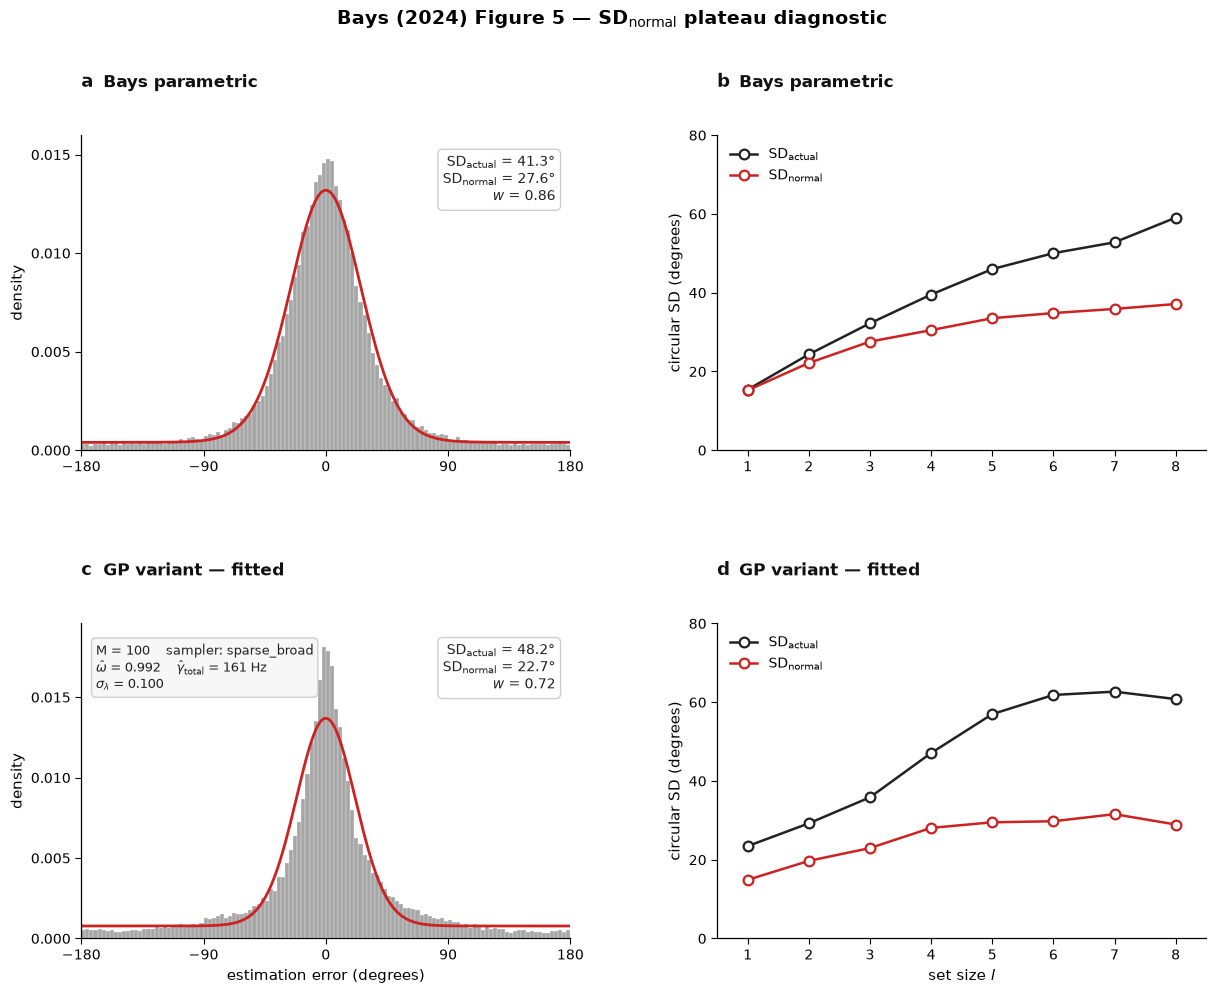

In [16]:
# Style -- match Bays Fig 5: SD_actual in black, SD_normal in red.
BLACK = "#222222"
RED   = "#CC2222"
GRAY  = "#777777"

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.9,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "font.family": "DejaVu Sans",
})


def mixture_pdf(eps_rad, w, kappa):
    """Normal+uniform mixture density on the circle (input in radians)."""
    vm = np.exp(kappa * np.cos(eps_rad)) / (2.0 * np.pi * i0(kappa))
    return w * vm + (1.0 - w) * (1.0 / (2.0 * np.pi))


# Shared axes infrastructure
edges_deg    = np.linspace(-180, 180, HIST_N_BINS + 1)
eps_grid_deg = np.linspace(-180, 180, 500)
eps_grid_rad = np.deg2rad(eps_grid_deg)

ns = np.array(SET_SIZES, dtype=float)
sd_actual_bays = np.array([np.rad2deg(bays_results[N]["sd_actual"]) for N in SET_SIZES])
sd_normal_bays = np.array([np.rad2deg(bays_results[N]["sd_normal"]) for N in SET_SIZES])
sd_actual_gp   = np.array([np.rad2deg(gp_results[N]["sd_actual"])   for N in SET_SIZES])
sd_normal_gp   = np.array([np.rad2deg(gp_results[N]["sd_normal"])   for N in SET_SIZES])

# --- Refined y-axis for the SD-vs-l panels -----------------------------
y_max_raw = max(sd_actual_bays.max(), sd_actual_gp.max())
Y_TICK_STRIDE = 20
Y_MAX_B = int(np.ceil(y_max_raw / Y_TICK_STRIDE) * Y_TICK_STRIDE)
Y_TICKS_B = np.arange(0, Y_MAX_B + 1, Y_TICK_STRIDE)

# Suppress automatic grids in this style block
plt.rc("axes", grid=False)
# ----------------------------------------------------------------------

fig = plt.figure(figsize=(12.5, 10.5))
gs = gridspec.GridSpec(
    2, 2,
    hspace=0.55, wspace=0.30,
    left=0.075, right=0.975, bottom=0.075, top=0.84,
)


def _panel_header(ax, letter, model, caption, show_xlabel_pad=False):
    """Two-line panel header: bold letter + model on line 1, caption on line 2."""
    ax.set_title("")
    ax.text(
        0.0, 1.14, f"{letter}",
        transform=ax.transAxes, ha="left", va="bottom",
        fontsize=13, fontweight="bold", color="#111111",
    )
    ax.text(
        0.045, 1.14, model,
        transform=ax.transAxes, ha="left", va="bottom",
        fontsize=12, fontweight="bold", color="#111111",
    )
    ax.text(
        0.0, 1.02, caption,
        transform=ax.transAxes, ha="left", va="bottom",
        fontsize=10, color="#555555",
    )


def plot_panel_a(ax, all_errors_rad, w, kappa, sd_actual_rad, sd_normal_rad,
                 letter, model, show_xlabel=True):
    """Aggregate error distribution + mixture overlay (degrees)."""
    all_errors_deg = np.rad2deg(all_errors_rad)
    counts, _, _ = ax.hist(all_errors_deg, bins=edges_deg, density=True,
            color=GRAY, alpha=0.65, edgecolor="white", linewidth=0.3)
    pdf_per_deg = mixture_pdf(eps_grid_rad, w, kappa) * (np.pi / 180.0)
    ax.plot(eps_grid_deg, pdf_per_deg, color=RED, lw=2.0)

    panel_y_max = max(counts.max(), pdf_per_deg.max()) * 1.08

    ax.set_xlim(-180, 180)
    ax.set_ylim(0, panel_y_max)
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=5, steps=[1, 2, 2.5, 5, 10]))
    if show_xlabel:
        ax.set_xlabel("estimation error (degrees)", fontsize=11)
    ax.set_ylabel("density", fontsize=11)
    ax.grid(False)
    _panel_header(ax, letter, model, caption="")

    ax.text(
        0.97, 0.94,
        f"SD$_\\mathrm{{actual}}$ = {np.rad2deg(sd_actual_rad):.1f}\u00b0\n"
        f"SD$_\\mathrm{{normal}}$ = {np.rad2deg(sd_normal_rad):.1f}\u00b0\n"
        f"$w$ = {w:.2f}",
        transform=ax.transAxes, ha="right", va="top",
        fontsize=10, color="#222222",
        bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#cccccc", alpha=0.95),
    )


def plot_panel_b(ax, sd_actual_arr, sd_normal_arr,
                 letter, model, show_xlabel=True):
    """SD_actual (black) vs SD_normal (red) across set sizes."""
    ax.plot(ns, sd_actual_arr, "o-", color=BLACK, lw=1.8, ms=7,
            label=r"SD$_\mathrm{actual}$", mfc="white", mew=1.6)
    ax.plot(ns, sd_normal_arr, "o-", color=RED, lw=1.8, ms=7,
            label=r"SD$_\mathrm{normal}$", mfc="white", mew=1.6)

    ax.set_xticks(SET_SIZES)
    ax.set_xlim(SET_SIZES[0] - 0.5, SET_SIZES[-1] + 0.5)
    ax.set_yticks(Y_TICKS_B)
    ax.set_ylim(0, Y_MAX_B)
    if show_xlabel:
        ax.set_xlabel("set size $l$", fontsize=11)
    ax.set_ylabel("circular SD (degrees)", fontsize=11)
    ax.legend(fontsize=10, loc="upper left", frameon=False)
    ax.grid(False)
    _panel_header(ax, letter, model, caption="")


# --- Row 1: Bays parametric ---
ax_1a = fig.add_subplot(gs[0, 0])
plot_panel_a(
    ax_1a, bays_all_errors, bays_w_agg, bays_kappa_agg,
    bays_sd_actual_agg, bays_sd_normal_agg,
    letter="a", model="Bays parametric",
    show_xlabel=False,
)

ax_1b = fig.add_subplot(gs[0, 1])
plot_panel_b(
    ax_1b, sd_actual_bays, sd_normal_bays,
    letter="b", model="Bays parametric",
    show_xlabel=False,
)

# --- Row 2: GP variant ---
# Panel labels now just say "GP variant — fitted". Sampler / M / fitted
# parameters live in the parameter callout below (on panel c) and in the
# figure's suptitle, not in the per-panel headers.
ax_2a = fig.add_subplot(gs[1, 0])
plot_panel_a(
    ax_2a, gp_all_errors, gp_w_agg, gp_kappa_agg,
    gp_sd_actual_agg, gp_sd_normal_agg,
    letter="c", model="GP variant — fitted",
    show_xlabel=True,
)

# Small parameter callout on panel c, lower-left, mirroring the
# SD/w callout already on the right. This is where the fitted-parameter
# numbers belong — in a small annotation, not in the title.
_sigma_label = {"folded_normal": r"$\sigma_\lambda$", "gamma": r"CV", "sparse_broad": r"$\sigma_\lambda$"}[DISTRIBUTION]
ax_2a.text(
    0.03, 0.94,
    f"M = {M}    sampler: {DISTRIBUTION}\n"
    f"$\\hat\\omega$ = {OMEGA_HAT:.3f}    "
    f"$\\hat\\gamma_\\mathrm{{total}}$ = {GAMMA_TOTAL_HAT:.0f} Hz\n"
    f"{_sigma_label} = {SIGMA_HAT:.3f}",
    transform=ax_2a.transAxes, ha="left", va="top",
    fontsize=9, color="#222222", family="DejaVu Sans",
    bbox=dict(boxstyle="round,pad=0.35", fc="#f7f7f7", ec="#cccccc", alpha=0.95),
)

ax_2b = fig.add_subplot(gs[1, 1])
plot_panel_b(
    ax_2b, sd_actual_gp, sd_normal_gp,
    letter="d", model="GP variant — fitted",
    show_xlabel=True,
)

# Figure-level heading — short, descriptive. No parameter dump.
fig.suptitle(
    r"Bays (2024) Figure 5 — SD$_\mathrm{normal}$ plateau diagnostic",
    fontsize=14, fontweight="bold", y=0.96,
)

# Save into the timestamped result directory
fig_path = OUTPUT_DIR / f"bays_fig5_M{M}_{DISTRIBUTION}.png"
fig_path_pdf = OUTPUT_DIR / f"bays_fig5_M{M}_{DISTRIBUTION}.pdf"
plt.savefig(fig_path,     dpi=160, bbox_inches="tight")
plt.savefig(fig_path_pdf,              bbox_inches="tight")
print(f"Saved {fig_path}")
print(f"Saved {fig_path_pdf}")
plt.show()


### Per-set-size error histograms — GP variant (illustrative, seed 0)

A 1×5 strip showing the empirical error density for the GP forward model at
$l \in \{1, 2, 4, 6, 8\}$ for seed 0, with the fitted Zhang & Luck mixture overlaid in
red. Not used in the thesis.

Wrote /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2024/result_data/bays_fig5_20261020_211045_1f544647/gp_error_histograms_M100_sparse_broad.png


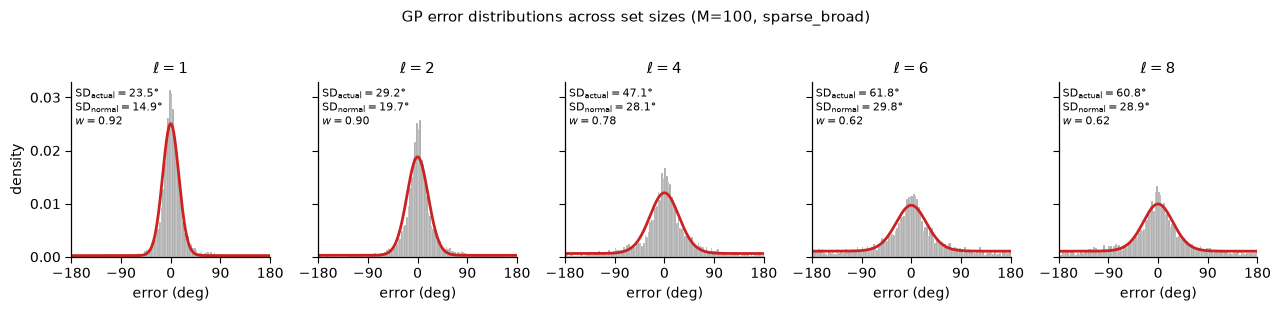

In [17]:
# Set sizes to display. Bays Fig 4 / Z&L convention: powers of two-ish.
HIST_SET_SIZES = [1, 2, 4, 6, 8]

# --- Self-contained plotting infrastructure --------------------------
# Mirror the pattern already used by the 8-panel comparison cell: define
# the shared histogram grid, the mixture density, and the colours locally
# so this cell runs on its own, regardless of whether the "Style" cell
# above was executed in the current kernel. (This is what previously
# caused a NameError on `edges_deg` after a kernel restart / out-of-order
# run.) When those names already exist, the values here are identical.
_n_bins = globals().get("HIST_N_BINS", 120)
edges_deg    = np.linspace(-180, 180, _n_bins + 1)
eps_grid_deg = np.linspace(-180, 180, 500)
eps_grid_rad = np.deg2rad(eps_grid_deg)

GRAY = globals().get("GRAY", "#777777")
RED  = globals().get("RED",  "#CC2222")

if "mixture_pdf" not in globals():
    def mixture_pdf(eps_rad, w, kappa):
        """Normal+uniform mixture density on the circle (input in radians)."""
        vm = np.exp(kappa * np.cos(eps_rad)) / (2.0 * np.pi * i0(kappa))
        return w * vm + (1.0 - w) * (1.0 / (2.0 * np.pi))
# ---------------------------------------------------------------------

fig, axes = plt.subplots(
    1, len(HIST_SET_SIZES),
    figsize=(2.6 * len(HIST_SET_SIZES), 3.0),
    sharey=True,
)

for ax, N in zip(axes, HIST_SET_SIZES):
    r = gp_results[N]
    errs_deg = np.rad2deg(r['errors'])

    # Gray histogram (matches panel a).
    ax.hist(errs_deg, bins=edges_deg, density=True,
            color=GRAY, alpha=0.65, edgecolor='white', linewidth=0.3)

    # Red mixture overlay — convert per-radian PDF to per-degree.
    pdf_per_deg = mixture_pdf(eps_grid_rad, r['w'], r['kappa']) * (np.pi / 180.0)
    ax.plot(eps_grid_deg, pdf_per_deg, color=RED, lw=2.0)

    ax.set_title(rf'$\ell = {N}$', fontsize=11)
    ax.set_xlim(-180, 180)
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_xlabel(r'error (deg)')

    ax.text(
        0.02, 0.97,
        f'$\\mathrm{{SD}}_\\mathrm{{actual}}={np.rad2deg(r["sd_actual"]):.1f}\\degree$\n'
        f'$\\mathrm{{SD}}_\\mathrm{{normal}}={np.rad2deg(r["sd_normal"]):.1f}\\degree$\n'
        f'$w={r["w"]:.2f}$',
        transform=ax.transAxes, fontsize=8, va='top', ha='left',
    )

axes[0].set_ylabel('density')
fig.suptitle(
    f'GP error distributions across set sizes '
    f'(M={M}, {DISTRIBUTION})',
    y=1.02, fontsize=11,
)
fig.tight_layout()

hist_path = OUTPUT_DIR / f'gp_error_histograms_M{M}_{DISTRIBUTION}.png'
fig.savefig(hist_path, dpi=180, bbox_inches='tight')
print(f'Wrote {hist_path}')
plt.show()


### Diagnostic moments vs set size — sweep one parameter at a time

A 3×3 grid:

- **Rows** are the statistics: circular variance, circular kurtosis (Fisher 1995), and
  $w_\mathrm{uniform} = 1 - w_\mathrm{vM}$ from the Zhang & Luck fit.
- **Columns** are the swept parameter, varied *one at a time* while the other two are held
  at the across-seed central fitted values (geometric mean of $\hat\lambda$ and
  $\hat\gamma$, mean of $\hat\sigma$), so every seed is swept over the same values:
  a) $\lambda$, b) $\gamma_{\text{per neuron}}$, c) $\sigma$ — the heterogeneity knob.

Each seed uses its own population; points are means over seeds with 95% confidence
intervals.

In [18]:
# === One-parameter sweeps for the diagnostic grid, at every population seed ===
# Arrays: sweep_lambda / sweep_gamma / sweep_sigma, shape (seeds, n_values, n_set_sizes, 3);
# last axis: 0 = circular variance, 1 = circular kurtosis, 2 = (1 - w_vM).
SWEEP_N_TRIALS = N_TRIALS     # trials per (value, set size); lower to go faster


def _circ_variance(errors):
    R = np.abs(np.mean(np.exp(1j * np.asarray(errors))))
    return -2.0 * np.log(max(R, 1e-15))


def _circ_kurtosis(errors):
    e = np.asarray(errors)
    m1, m2 = np.mean(np.exp(1j * e)), np.mean(np.exp(2j * e))
    rho1 = np.abs(m1)
    num = np.abs(m2) * np.cos(np.angle(m2) - 2 * np.angle(m1)) - rho1 ** 4
    den = (1.0 - rho1) ** 2
    return num / den


def _metrics_from_errors(errors):
    """(circular variance, circular kurtosis, 1 - w_vM) for one error pool."""
    w_hat, _kappa, _sd = fit_normal_uniform_mixture(errors)
    return _circ_variance(errors), _circ_kurtosis(errors), 1.0 - w_hat


def _errors_for(pop, set_size, gamma, pop_seed):
    """Run the trial engine as before (trial seed = population seed + set size)."""
    return gp_errors(pop, gamma, set_size, SWEEP_N_TRIALS, pop_seed + set_size)


# --- Anchor: across-seed central fitted values; swept grids clipped to the fit bounds ---
LAMBDA_ANCHOR = float(np.exp(np.mean(np.log([f["lambda"] for f in FITS]))))
GAMMA_ANCHOR  = float(np.exp(np.mean(np.log([f["gamma_pn"] for f in FITS]))))
SIGMA_ANCHOR  = float(np.mean([f["sigma"] for f in FITS]))
LAMBDA_SWEEP = np.clip(LAMBDA_ANCHOR * np.array([0.6, 0.8, 1.0, 1.3]), LO[0], HI[0])
GAMMA_SWEEP  = np.clip(GAMMA_ANCHOR * np.array([0.5, 0.75, 1.0, 1.5]), LO[1], HI[1])
if SIGMA_NAME == "cv":
    SIGMA_SWEEP = np.clip(np.array([0.05, 0.2, 0.5, 1.0]), LO[2], HI[2])
else:  # sigma_lambda (folded_normal / sparse_broad)
    SIGMA_SWEEP = np.clip(np.array([0.0, 0.1, 0.3, 0.6]), LO[2], HI[2])

n_ss = len(SET_SIZES)
sweep_lambda = np.empty((N_SEEDS, len(LAMBDA_SWEEP), n_ss, 3))
sweep_gamma  = np.empty((N_SEEDS, len(GAMMA_SWEEP),  n_ss, 3))
sweep_sigma  = np.empty((N_SEEDS, len(SIGMA_SWEEP),  n_ss, 3))

t0 = time.time()
print(f"Sweeping around lambda={LAMBDA_ANCHOR:.3f}, gamma/neuron={GAMMA_ANCHOR:.3f}, "
      f"{SIGMA_NAME}={SIGMA_ANCHOR:.3f}; {SWEEP_N_TRIALS} trials/point; {N_SEEDS} seeds.")
for s, pop_seed in enumerate(SEED_BASES):
    for j, lam in enumerate(LAMBDA_SWEEP):                 # rebuild per value
        pop = gp_population(lam, SIGMA_ANCHOR, pop_seed)
        for k, N in enumerate(SET_SIZES):
            sweep_lambda[s, j, k, :] = _metrics_from_errors(_errors_for(pop, N, GAMMA_ANCHOR, pop_seed))
    pop_fixed = gp_population(LAMBDA_ANCHOR, SIGMA_ANCHOR, pop_seed)   # gamma only changes the gain
    for j, gam in enumerate(GAMMA_SWEEP):
        for k, N in enumerate(SET_SIZES):
            sweep_gamma[s, j, k, :] = _metrics_from_errors(_errors_for(pop_fixed, N, gam, pop_seed))
    for j, sig in enumerate(SIGMA_SWEEP):                  # rebuild per value
        pop = gp_population(LAMBDA_ANCHOR, sig, pop_seed)
        for k, N in enumerate(SET_SIZES):
            sweep_sigma[s, j, k, :] = _metrics_from_errors(_errors_for(pop, N, GAMMA_ANCHOR, pop_seed))
    print(f"  seed {s} done ({time.time() - t0:.0f}s)")

print(f"Sweeps done in {time.time() - t0:.1f}s.")
print(f"  LAMBDA_SWEEP = {np.round(LAMBDA_SWEEP, 3)}")
print(f"  GAMMA_SWEEP  = {np.round(GAMMA_SWEEP, 3)}")
print(f"  SIGMA_SWEEP  = {np.round(SIGMA_SWEEP, 3)}  ({SIGMA_NAME})")

Sweeping around lambda=1.405, gamma/neuron=2.240, sigma_lambda=0.100; 5000 trials/point; 10 seeds.
  seed 0 done (8s)
  seed 1 done (15s)
  seed 2 done (23s)
  seed 3 done (30s)
  seed 4 done (37s)
  seed 5 done (45s)
  seed 6 done (52s)
  seed 7 done (60s)
  seed 8 done (67s)
  seed 9 done (75s)
Sweeps done in 74.5s.
  LAMBDA_SWEEP = [0.843 1.124 1.405 1.826]
  GAMMA_SWEEP  = [1.12 1.68 2.24 3.36]
  SIGMA_SWEEP  = [0.  0.1 0.3 0.6]  (sigma_lambda)


Saved:
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2024/result_data/bays_fig5_20261020_211045_1f544647/gp_sweep_var_kurt_wuni_M100_sparse_broad_10seeds.png
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2024/result_data/bays_fig5_20261020_211045_1f544647/gp_sweep_var_kurt_wuni_M100_sparse_broad_10seeds.pdf
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/zhang_luck/gp_sweep_var_kurt_wuni_M100_sparse_broad.png
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/zhang_luck/gp_sweep_var_kurt_wuni_M100_sparse_broad.pdf
  For the caption: set size on a linear axis; variance and 1-w rows linear; kurtosis row log. Lines are means over 10 population seeds with 95% confidence intervals; non-swept

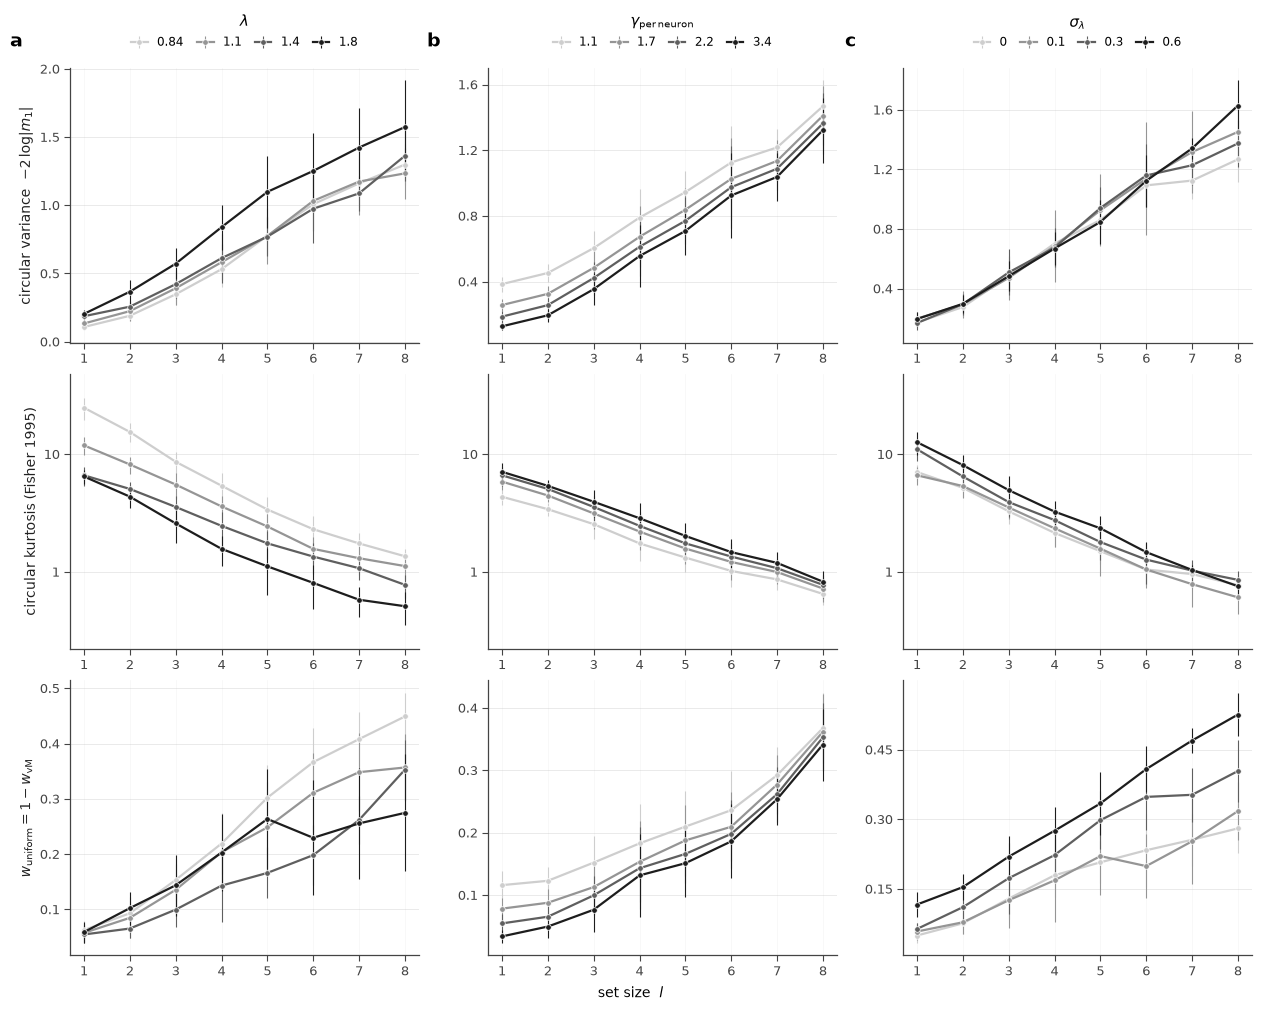

In [19]:
# Plot ---------------------------------------------------------------------
# TRANSPOSED LAYOUT: metrics are the 3 ROWS, the swept parameter is the 3 COLUMNS.
# Lines are means over seeds; thin bars are 95% confidence intervals across seeds.
import matplotlib as mpl

# Display symbol for the heterogeneity knob (the sigma column).
_sigma_escaped = SIGMA_NAME.replace("_", r"\_")
SIGMA_SYM = {
    'sigma_lambda': r'\sigma_\lambda',
    'cv':           r'\mathrm{CV}',
}.get(SIGMA_NAME, r'\sigma_{\mathrm{' + _sigma_escaped + r'}}')

# --- One entry per swept parameter -> these are the COLUMNS. ---
COLS = [
    (sweep_lambda, LAMBDA_SWEEP, r'\lambda'),
    (sweep_gamma,  GAMMA_SWEEP,  r'\gamma_{\mathrm{per\,neuron}}'),
    (sweep_sigma,  SIGMA_SWEEP,  SIGMA_SYM),
]
COL_LABELS = ['a', 'b', 'c']

# --- One entry per METRIC -> these are the ROWS (index, label). ---
ROWS = [
    (0, r'circular variance  $-2\,\log|m_1|$'),
    (1, r'circular kurtosis (Fisher 1995)'),
    (2, r'$w_\mathrm{uniform} = 1 - w_\mathrm{vM}$'),
]

# Kurtosis row: log axis only if every plotted value (including CIs) is positive.
_kv = []
for grid, _values, _sym in COLS:
    _kv += [t.ravel() for t in mean_ci(grid[..., 1])]
KURT_SPEC = kurtosis_axis_spec(np.concatenate(_kv))

# --- Monochrome grey ramp: light = low value, dark = high value. ---
_GREYS = mpl.colormaps['Greys']
def _grey_ramp(k):
    if k <= 1:
        return [_GREYS(0.62)]
    return [_GREYS(0.30 + 0.60 * j / (k - 1)) for j in range(k)]

mpl.rcParams.update({
    'font.size':       10,
    'axes.edgecolor':  '#444444',
    'axes.linewidth':  0.9,
    'axes.labelcolor': '#222222',
    'xtick.color':     '#444444',
    'ytick.color':     '#444444',
    'legend.frameon':  False,
})

fig, axes = plt.subplots(3, 3, figsize=(12.5, 10.0), sharex=True,
                         constrained_layout=True)

for ci_row, (metric_idx, metric_long) in enumerate(ROWS):
    for cj, (grid, values, sym) in enumerate(COLS):
        ax = axes[ci_row, cj]
        colors = _grey_ramp(len(values))
        m, lo, hi = mean_ci(grid[..., metric_idx])           # each (n_values, n_set_sizes)
        for j, v in enumerate(values):
            ax.errorbar(SET_SIZES, m[j], yerr=np.vstack([m[j] - lo[j], hi[j] - m[j]]),
                        marker='o', ms=4.0, lw=1.6, color=colors[j],
                        elinewidth=0.8, capsize=0,
                        markeredgecolor='white', markeredgewidth=0.5,
                        label=f'${v:.2g}$', zorder=3)
        if metric_idx == 1:
            if KURT_SPEC[0] == 'log':
                log_y_axis(ax, KURT_SPEC[1], KURT_SPEC[2])
            else:
                ax.set_ylim(KURT_SPEC[1], KURT_SPEC[2])
                ax.yaxis.set_major_locator(MaxNLocator(nbins=5, min_n_ticks=2))
        else:
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5, min_n_ticks=2))
        ax.set_xticks(SET_SIZES)
        ax.tick_params(labelbottom=True)                    # labelled ticks on every panel
        ax.set_xlim(min(SET_SIZES) - 0.3, max(SET_SIZES) + 0.3)
        ax.grid(True, which='major', axis='y', alpha=0.30, lw=0.6)
        ax.grid(True, which='major', axis='x', alpha=0.12, lw=0.5)
        ax.tick_params(axis='both', labelsize=9)
        for side in ('top', 'right'):
            ax.spines[side].set_visible(False)
        if cj == 0:
            ax.set_ylabel(metric_long, fontsize=10)

# --- One legend per column, above each column: symbol as the title. ---
for cj, (grid, values, sym) in enumerate(COLS):
    handles, labels = axes[0, cj].get_legend_handles_labels()
    axes[0, cj].legend(
        handles, labels,
        loc='lower center', bbox_to_anchor=(0.5, 1.03),
        ncol=min(len(values), 4), fontsize=8.5,
        columnspacing=1.1, handlelength=1.4,
        title=rf'${sym}$', title_fontsize=10.5,
    )
    axes[0, cj].annotate(
        COL_LABELS[cj],
        xy=(0, 1), xycoords='axes fraction',
        xytext=(-34, 12), textcoords='offset points',
        ha='right', va='bottom', fontsize=14, fontweight='bold',
    )

fig.supxlabel(r'set size  $l$', fontsize=10)

_thesis = 'zhang_grid_search' if DISTRIBUTION == 'gamma' else f'gp_sweep_var_kurt_wuni_M{M}_{DISTRIBUTION}'
saved = save_with_thesis_copy(fig, f'gp_sweep_var_kurt_wuni_M{M}_{DISTRIBUTION}_{N_SEEDS}seeds', _thesis)
print('Saved:\n  ' + '\n  '.join(str(p) for p in saved))
print(f'  For the caption: set size on a linear axis; variance and 1-w rows linear; '
      f'kurtosis row {KURT_SPEC[0]}. Lines are means over {N_SEEDS} population seeds with '
      f'95% confidence intervals; non-swept parameters held at the across-seed central fit '
      f'(lambda={LAMBDA_ANCHOR:.3f}, gamma/neuron={GAMMA_ANCHOR:.3f}, {SIGMA_NAME}={SIGMA_ANCHOR:.3f}).')
plt.show()

## Bays vs GP — eight-panel comparison (thesis figure)

Left column: the Bays parametric model; right column: the GP variant.

1. **Aggregate error histogram** (seed 0) with the fitted Zhang & Luck mixture; the box gives
   the mean [95% CI] across seeds of the pooled statistics.
2. **Single-item histogram** ($l = 1$, seed 0), with the same summary box.
3. **SD line plot** — $\mathrm{SD}_{\mathrm{actual}}$ vs $\mathrm{SD}_{\mathrm{normal}}$ across set
   sizes (the plateau diagnostic), means with 95% CIs.
4. **Guess rate** — the mixture's uniform weight $1 - w$ across set sizes, means with 95% CIs.

Bays intervals are across trial replicates; GP intervals are across population seeds.

Saved:
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2024/result_data/bays_fig5_20261020_211045_1f544647/bays_vs_gp_8panel_M100_sparse_broad_10seeds.png
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2024/result_data/bays_fig5_20261020_211045_1f544647/bays_vs_gp_8panel_M100_sparse_broad_10seeds.pdf
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/zhang_luck/zhang_8_panel_sparse_broad.png
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/zhang_luck/zhang_8_panel_sparse_broad.pdf
  For the caption: all axes linear. Rows a and b show one example (seed 0), with its statistics in the boxes; rows c and d are means with 95% CIs over 10 population seeds (mixed selectivity) and 10 trial replicate

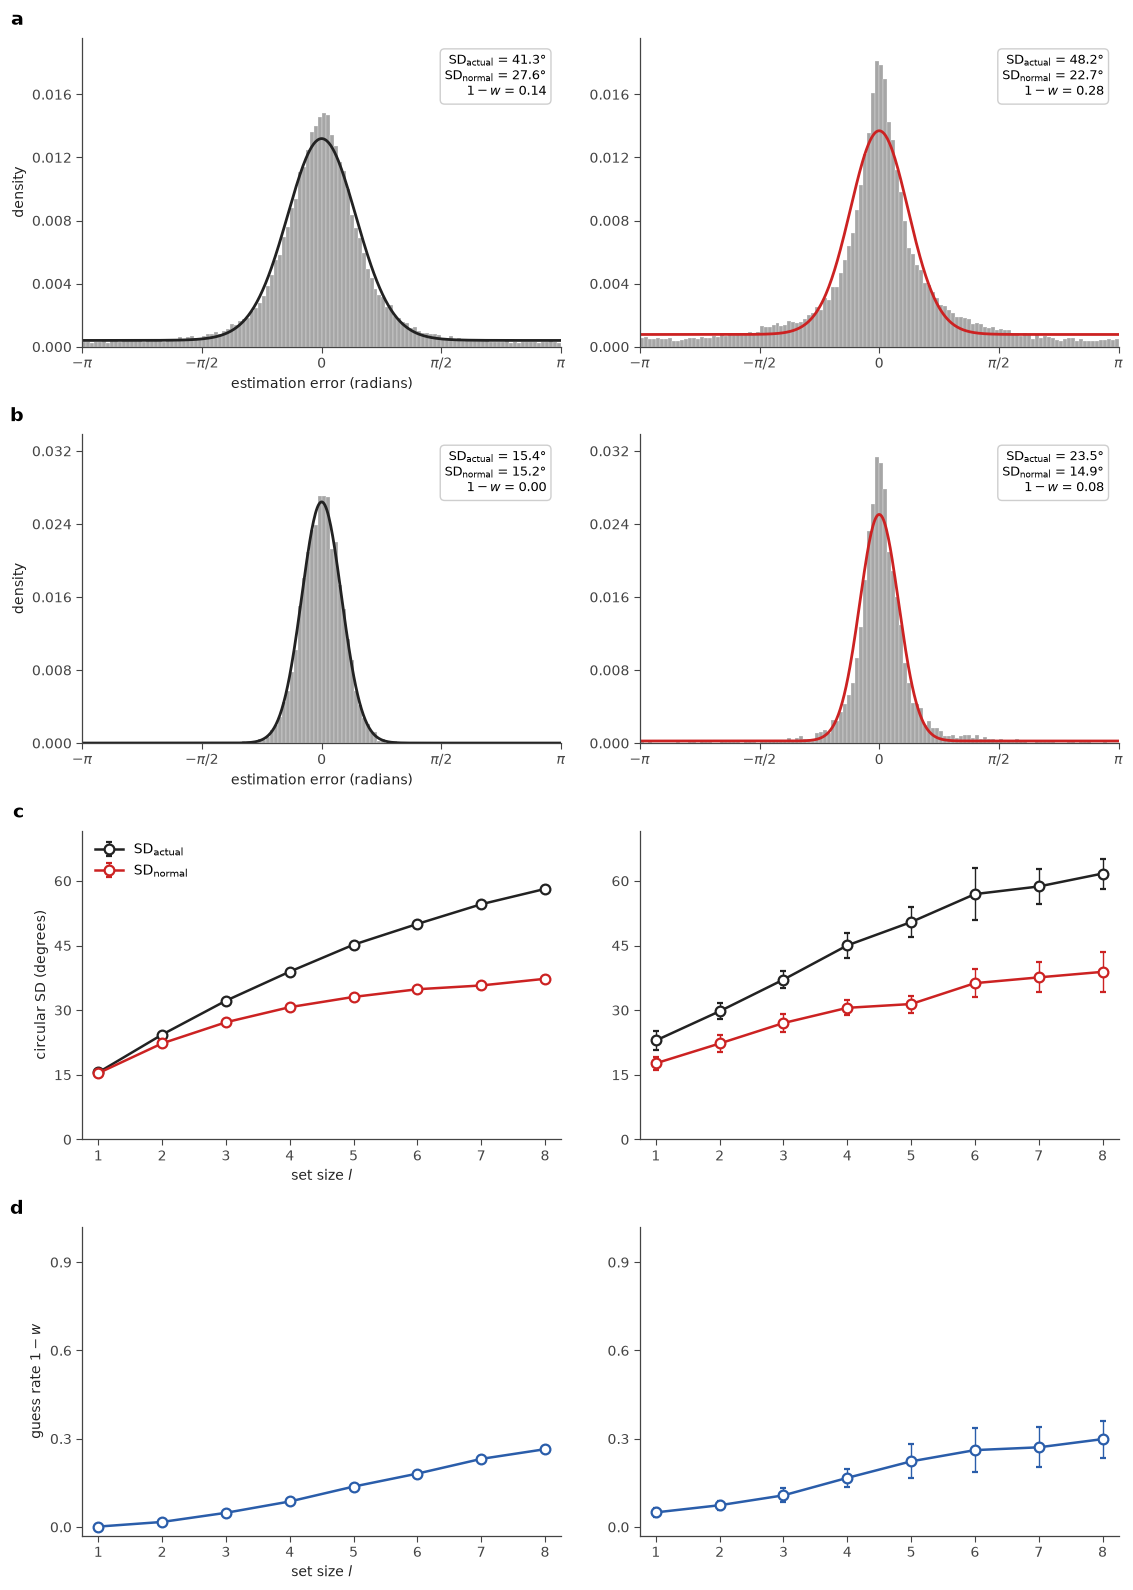

In [20]:
# === Bays vs GP - eight-panel comparison (4x2 grid), with confidence intervals ===
from scipy.special import i0 as _i0
from matplotlib.ticker import MaxNLocator

GRAY  = "#777777"
RED   = "#CC2222"
BLACK = "#222222"
BLUE  = "#2A5DAA"


def _mixture_pdf(eps_rad, w, kappa):
    """Normal+uniform mixture density on the circle (radians)."""
    vm = np.exp(kappa * np.cos(eps_rad)) / (2.0 * np.pi * _i0(kappa))
    return w * vm + (1.0 - w) * (1.0 / (2.0 * np.pi))


_edges_deg    = np.linspace(-180, 180, HIST_N_BINS + 1)
_eps_grid_deg = np.linspace(-180, 180, 500)
_eps_grid_rad = np.deg2rad(_eps_grid_deg)
_deg_scale    = np.pi / 180.0
_ns = np.array(SET_SIZES, dtype=float)

# Across-seed summaries: (mean, lo, hi) arrays over set sizes.
CI = {model: {k: mean_ci(v) for k, v in CURVES[model].items()} for model in ("Bays", "GP")}


def _hist_peak(errors, w, kappa):
    dens, _ = np.histogram(np.rad2deg(errors), bins=_edges_deg, density=True)
    pdf = _mixture_pdf(_eps_grid_rad, w, kappa) * _deg_scale
    return max(dens.max(), pdf.max())

_b1, _g1 = bays_results[1], gp_results[1]          # seed 0

agg_top = max(_hist_peak(bays_all_errors, bays_w_agg, bays_kappa_agg),
              _hist_peak(gp_all_errors,   gp_w_agg,   gp_kappa_agg)) * 1.08
l1_top  = max(_hist_peak(_b1["errors"], _b1["w"], _b1["kappa"]),
              _hist_peak(_g1["errors"], _g1["w"], _g1["kappa"])) * 1.08
sd_top  = max(CI[m][k][2].max() for m in ("Bays", "GP") for k in ("sd_actual", "sd_normal")) * 1.10
xlim_setsize = (SET_SIZES[0] - 0.25, SET_SIZES[-1] + 0.25)

fig, axes = plt.subplots(4, 2, figsize=(11.5, 16.0))


def _draw_hist(ax, errors, w, kappa, ytop, curve_color=RED,
               show_xlabel=True, show_ylabel=True):
    ax.hist(np.rad2deg(errors), bins=_edges_deg, density=True,
            color=GRAY, alpha=0.65, edgecolor="white", linewidth=0.3)
    pdf = _mixture_pdf(_eps_grid_rad, w, kappa) * _deg_scale
    ax.plot(_eps_grid_deg, pdf, color=curve_color, lw=2.0)
    ax.set_xlim(-180, 180)
    # Data are binned in degrees; tick labels are written in radians.
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
    ax.set_ylim(0.0, ytop)
    if show_xlabel:
        ax.set_xlabel("estimation error (radians)")
    if show_ylabel:
        ax.set_ylabel("density")


def _thin_yticks(ax, reduce_by=2, min_ticks=3):
    """Aesthetics only: fewer y-ticks, never fewer than min_ticks labelled."""
    lo, hi = ax.get_ylim()
    inview = lambda ts: [t for t in ts if lo - 1e-9 <= t <= hi + 1e-9]
    before = len(inview(ax.get_yticks()))
    desired = max(before - reduce_by, min_ticks)
    best = None
    for nb in range(1, before + 3):
        cnt = len(inview(MaxNLocator(nbins=nb).tick_values(lo, hi)))
        key = (cnt != desired, abs(cnt - desired), cnt > desired)
        if best is None or key < best[0]:
            best = (key, nb)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=best[1]))
    ax.set_ylim(lo, hi)


def _annot(ax, sd_a, sd_n, w):
    """Summary box for the histogram shown (seed 0), as in the original figure."""
    ax.text(
        0.97, 0.95,
        f"SD$_\\mathrm{{actual}}$ = {np.rad2deg(sd_a):.1f}\u00b0\n"
        f"SD$_\\mathrm{{normal}}$ = {np.rad2deg(sd_n):.1f}\u00b0\n"
        f"$1-w$ = {1.0 - w:.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#cccccc", alpha=0.95),
    )


def _errorbar(ax, triple, color, label=None):
    m, lo, hi = triple
    ax.errorbar(_ns, m, yerr=np.vstack([m - lo, hi - m]), fmt="o-", color=color, lw=1.8,
                ms=7, mfc="white", mew=1.6, elinewidth=1.0, capsize=2.5, label=label,
                zorder=3)


def _draw_sd(ax, model, show_xlabel=True, show_ylabel=True, show_legend=True):
    _errorbar(ax, CI[model]["sd_actual"], BLACK, r"SD$_\mathrm{actual}$")
    _errorbar(ax, CI[model]["sd_normal"], RED, r"SD$_\mathrm{normal}$")
    ax.set_xticks(SET_SIZES)
    ax.set_xlim(*xlim_setsize)
    ax.set_ylim(0.0, sd_top)
    if show_xlabel:
        ax.set_xlabel(r"set size $l$")
    if show_ylabel:
        ax.set_ylabel("circular SD (degrees)")
    if show_legend:
        ax.legend(fontsize=10, loc="upper left", frameon=False)


def _draw_guess(ax, model, show_xlabel=True, show_ylabel=True):
    _errorbar(ax, CI[model]["guess"], BLUE)
    ax.set_xticks(SET_SIZES)
    ax.set_xlim(*xlim_setsize)
    ax.set_ylim(-0.03, 1.02)
    if show_xlabel:
        ax.set_xlabel(r"set size $l$")
    if show_ylabel:
        ax.set_ylabel(r"guess rate $1-w$")      # 1 - w is the uniform (guess) weight


# --- Row 1: aggregate ("collated") histograms, seed 0 ---
_draw_hist(axes[0, 0], bays_all_errors, bays_w_agg, bays_kappa_agg, agg_top,
           curve_color=BLACK, show_xlabel=True, show_ylabel=True)
_annot(axes[0, 0], bays_sd_actual_agg, bays_sd_normal_agg, bays_w_agg)
_draw_hist(axes[0, 1], gp_all_errors, gp_w_agg, gp_kappa_agg, agg_top,
           show_xlabel=False, show_ylabel=False)
_annot(axes[0, 1], gp_sd_actual_agg, gp_sd_normal_agg, gp_w_agg)

# --- Row 2: single-item histograms (l = 1), seed 0 ---
_draw_hist(axes[1, 0], _b1["errors"], _b1["w"], _b1["kappa"], l1_top,
           curve_color=BLACK, show_xlabel=True, show_ylabel=True)
_annot(axes[1, 0], _b1["sd_actual"], _b1["sd_normal"], _b1["w"])
_draw_hist(axes[1, 1], _g1["errors"], _g1["w"], _g1["kappa"], l1_top,
           show_xlabel=False, show_ylabel=False)
_annot(axes[1, 1], _g1["sd_actual"], _g1["sd_normal"], _g1["w"])

# --- Row 3: SD_actual vs SD_normal (means, 95% CI) ---
_draw_sd(axes[2, 0], "Bays", show_xlabel=True, show_ylabel=True, show_legend=True)
_draw_sd(axes[2, 1], "GP", show_xlabel=False, show_ylabel=False, show_legend=False)

# --- Row 4: guess rate 1 - w (means, 95% CI) ---
_draw_guess(axes[3, 0], "Bays", show_xlabel=True, show_ylabel=True)
_draw_guess(axes[3, 1], "GP", show_xlabel=False, show_ylabel=False)

for _r, _lab in enumerate(["a", "b", "c", "d"]):
    axes[_r, 0].annotate(
        _lab, xy=(0, 1), xycoords="axes fraction",
        xytext=(-42, 6), textcoords="offset points",
        ha="right", va="bottom", fontsize=14, fontweight="bold",
    )
fig.tight_layout()

fig.canvas.draw()
for _ax in axes.flat:
    _thin_yticks(_ax, reduce_by=2)

_thesis = 'zhang_8_panel' if DISTRIBUTION == 'gamma' else f'zhang_8_panel_{DISTRIBUTION}'
saved = save_with_thesis_copy(fig, f"bays_vs_gp_8panel_M{M}_{DISTRIBUTION}_{N_SEEDS}seeds", _thesis)
print('Saved:\n  ' + '\n  '.join(str(p) for p in saved))
print(f'  For the caption: all axes linear. Rows a and b show one example (seed 0), with its '
      f'statistics in the boxes; rows c and d are means with 95% CIs over {N_SEEDS} '
      f'population seeds (mixed selectivity) and {N_SEEDS} trial replicates (Bays).')
plt.show()

In [21]:
# === Save raw per-seed results ===
import pickle

raw_path = OUTPUT_DIR / "zhang_luck_seed_results.pkl"
with open(raw_path, "wb") as fh:
    pickle.dump({
        "config": _fit_config, "N_SEEDS": N_SEEDS, "SEED_BASES": SEED_BASES,
        "noise_floor": NOISE_FLOOR, "fits": FITS,
        "bays_by_seed": BAYS_BY_SEED, "gp_by_seed": GP_BY_SEED,
        "curves": CURVES, "aggregate": AGG,
        "claim_tests": CLAIM_TESTS, "gp_minus_bays": GP_MINUS_BAYS,
        "sensitivity": {"lambda": (LAMBDA_SWEEP, sweep_lambda), "gamma": (GAMMA_SWEEP, sweep_gamma),
                        "sigma": (SIGMA_SWEEP, sweep_sigma),
                        "anchor": (LAMBDA_ANCHOR, GAMMA_ANCHOR, SIGMA_ANCHOR)},
    }, fh)
print(f"Saved {raw_path}")

Saved /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2024/result_data/bays_fig5_20261020_211045_1f544647/zhang_luck_seed_results.pkl
